# Kvasir-SEG — standalone, review ke mutabiq (architecture, XAI, robustness, ablation, SOTA, cross-dataset)

**Sirf Kvasir-SEG train hota hai is notebook mein.** CVC-ClinicDB training, pooled training, aur federated learning doosri (CVC) notebook mein hain — unhe is file mein dobara nahi kiya gaya.
CVC-ClinicDB, CVC-ColonDB, ETIS-LaribPolypDB aur CVC-300 ka sirf **test** split yahan load hota hai — sirf Kvasir-trained model ko **zero-shot cross-dataset generalisation** ke liye test karne ke vaaste (koi training nahi).

**Reviewer ke Kvasir-specific issues jo is notebook mein resolve kiye gaye hain:**
1. **Architecture (review §2.3):** reviewer ke apne evidence ne dikhaya tha ke complex decoder (ASPP + attention-gate + CBAM + deep supervision) plain ResNet-50 U-Net se behtar nahi. Is liye **plain ResNet-50 U-Net hi main/proposed model hai**; complex architecture sirf ablation mein hai (A6), taake ye claim dobara, sahi (bug-free preprocessing, matched epochs, proper multi-seed stats) test ho sake.
2. **SOTA comparison (review §2.2):** mDice/mIoU (per-image average), PraNet protocol, aur Kvasir table mein pehle missing HarDNet-MSEG aur UACANet-S/L baselines add kiye.
3. **XAI (review §2.6):** Grad-CAM++ (asli), ek hi decoder layer (`dec4_relu2`) **dono architectures (plain + complex) par**, top-g% threshold (IoU ceiling = 1), AUPRC, n ≥ 100 Grad-CAM++ images (poora Kvasir test set), LIME 150 segments × 1000 samples (n ≥ 50), deletion/insertion AUC, model-randomisation sanity check, mean ± 95% bootstrap CI.
4. **Robustness (review §2.8):** poora test set (n=150, 40 nahi), severity 0 (clean) column, relative robustness (corrupted/clean) ratio.
5. **Statistics (review §2.5):** per-image Dice pehle seeds par average, phir ek paired Wilcoxon + Holm correction + bootstrap 95% CI — seed × image pseudo-replication nahi.
6. **Cross-dataset generalisation (naya):** Kvasir-trained model zero-shot CVC-ClinicDB, CVC-300, CVC-ColonDB, ETIS par (C2 cross-dataset matrix wala idea, yahan Kvasir-row ke liye).
7. **Precision-Recall curve + bar graph (aapka ask):** A2 mein threshold-free PR curve (AUPRC) + 6-metric bar chart (Accuracy/Precision/Recall/Dice/IoU/F1), jaisa paper ka original Fig. 15.
8. **Dataset/client-heterogeneity plot (aapka ask):** C3 mein Kvasir vs CVC/ColonDB/ETIS ki apni properties (polyp size, brightness) — koi CVC model train nahi hota, sirf images load hoti hain.
9. **Reproducibility:** split image-ID list export, near-duplicate sensitivity check, fixed seed=42 split, resume-capable training (kernel crash ho to dobara training nahi hogi).

**Kaise chalana:** `Run → Run All Cells`. Training resume-capable hai: agar weights + results disk par pehle se hain to wo seed SKIP ho jata hai.

In [26]:
import os
os.environ["CUDA_DEVICE_ORDER"]    = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [2]:
# ===== CELL 1: LIBRARIES INSTALL (EK BAAR chalao, phir Kernel -> Restart) =====
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError     # Python 3.8+

def _pip(*args):
    return subprocess.call([sys.executable, "-m", "pip", *args])

try:
    np_ver = version("numpy")
except PackageNotFoundError:
    np_ver = None
print("python", sys.version.split()[0], "| numpy", np_ver)

PKGS = ["opencv-python-headless",      # NOTE: headless -> libxcb / libGL error nahi aata
        "scikit-learn", "scipy", "pandas", "matplotlib",
        "scikit-image", "lime", "tqdm", "h5py"]

_pip("uninstall", "-y", "-q", "opencv-python", "opencv-python-headless", "opencv-contrib-python", "opencv-contrib-python-headless")
pins = [f"numpy=={np_ver}"] if np_ver else []
rc = _pip("install", "-q", *pins, *PKGS)
if rc != 0:
    print("Pin ke saath install fail hua -> bina pin ke dobara try kar raha hoon ...")
    rc = _pip("install", "-q", *PKGS)
print("INSTALL OK" if rc == 0 else "INSTALL FAILED -> upar wala error dekho")
print(">>> AB: Kernel -> Restart, phir Cell 2 (ENV CHECK) se aage chalao <<<")

python 3.8.10 | numpy 1.24.4


INSTALL OK
>>> AB: Kernel -> Restart, phir Cell 2 (ENV CHECK) se aage chalao <<<


In [27]:
import os
os.environ["CUDA_DEVICE_ORDER"]    = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_GPU_ALLOCATOR"]     = "cuda_malloc_async"

In [4]:
!free -h
!nvidia-smi

              total        used        free      shared  buff/cache   available
Mem:           62Gi        28Gi        15Gi       291Mi        19Gi        33Gi
Swap:         8.0Gi          0B       8.0Gi
Fri Oct  9 05:31:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3080        Off |   00000000:23:00.0 Off |                  N/A |
|  0%   32C    P8           

In [5]:
# ===== CELL 0: sab se khali GPU chunein (TensorFlow import hone se PEHLE) =====
import os, subprocess
out = subprocess.run("nvidia-smi --query-gpu=index,memory.free --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout
free = {int(l.split(",")[0]): int(l.split(",")[1]) for l in out.strip().splitlines() if l.strip()}
if free:
    best = max(free, key=free.get)
    os.environ["CUDA_VISIBLE_DEVICES"] = str(best)
    print("GPU free memory (MiB):", free, "-> GPU", best, "use hoga")
else:
    print("nvidia-smi se koi GPU list nahi mili (GPU-less machine ho sakti hai) -> CUDA_VISIBLE_DEVICES chhed nahi rahe; Cell 2 (ENV CHECK) aage confirm karega.")

GPU free memory (MiB): {0: 99, 1: 9634} -> GPU 1 use hoga


In [28]:
# ===== CELL 2: ENV CHECK (har library import karke dekhta hai; kuch missing ho to saaf bata deta hai) =====
import os, sys, importlib
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")
print("python", sys.version.split()[0])
need = [("tensorflow", "tensorflow"), ("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"),
        ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn"), ("skimage", "scikit-image"),
        ("cv2", "opencv-python-headless"), ("lime", "lime"), ("tqdm", "tqdm"), ("h5py", "h5py")]
bad = []
for mod, pipname in need:
    try:
        m = importlib.import_module(mod)
        print(f"  OK    {mod:11s} {getattr(m, '__version__', '')}")
    except Exception as e:
        bad.append((mod, pipname, e))
        print(f"  FAIL  {mod:11s} {type(e).__name__}: {str(e)[:110]}")

if bad:
    print("\n--- KAISE THEEK KAREIN ---")
    for mod, pipname, e in bad:
        if mod == "cv2" and any(k in str(e) for k in ("libxcb", "libGL", "libglib")):
            print("cv2: GUI libraries missing. Cell 1 dobara chalao (headless install) + Kernel Restart.")
            print("     Phir bhi na chale to:  !apt-get update -qq && apt-get install -y -qq libgl1 libglib2.0-0 libxcb1")
        else:
            print(f"{mod}: !pip install -q {pipname}   (phir Kernel -> Restart)")
    raise RuntimeError("Upar FAIL wali libraries theek karo, phir ye cell dobara chalao.")

import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("\nTensorFlow", tf.__version__, "| GPUs:", [g.name for g in gpus] if gpus else "NONE")
if not gpus:
    print("WARNING: GPU nahi mila -> training bohot slow hogi (CPU). QUICK_TEST se pehle GPU setup check karo.")
print("\nENV CHECK PASSED")

python 3.8.10
  OK    tensorflow  2.12.0
  OK    numpy       1.24.4
  OK    scipy       1.10.1
  OK    pandas      2.0.3
  OK    matplotlib  3.7.1
  OK    sklearn     1.3.2
  OK    skimage     0.21.0
  OK    cv2         5.0.0
  OK    lime        
  OK    tqdm        4.67.3
  OK    h5py        3.8.0

TensorFlow 2.12.0 | GPUs: ['/physical_device:GPU:0']

ENV CHECK PASSED


In [7]:
%%writefile common_utils.py
"""
common_utils.py  -- TensorFlow-FREE helpers shared by the CVC-ClinicDB and Kvasir-SEG notebooks.
Put this file in the SAME folder as the notebooks, then:   from common_utils import *

Contents
  1. file pairing / loading / CLAHE / split save+load
  2. pHash near-duplicate check (train vs test leakage detector)
  3. per-image metrics (mDice, mIoU ...) + bootstrap CI
  4. multi-seed statistics (seed-averaged per-image Dice, Wilcoxon, Holm)
  5. polyp-size stratification
  6. synthetic corruptions (severity 0..5)
  7. XAI metrics (pointing game, energy PG, top-g IoU, AUROC/AUPRC) + LIME heat-map + baselines
  8. HD95 + relative robustness
  9. display helpers (mean +- SD tables, violin plots, leakage report)
"""
import os, json
import numpy as np
import cv2
from scipy import ndimage, stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")


# ----------------------------------------------------------------------------
# 1. files / loading / split
# ----------------------------------------------------------------------------
def pair_files(img_dir, mask_dir):
    """Pair images and masks by base-name (extension-insensitive). Returns two sorted lists."""
    imgs = sorted(f for f in os.listdir(img_dir) if f.lower().endswith(IMG_EXTS))
    masks = {os.path.splitext(f)[0].lower(): f
             for f in os.listdir(mask_dir) if f.lower().endswith(IMG_EXTS)}
    ip, mp = [], []
    for f in imgs:
        k = os.path.splitext(f)[0].lower()
        if k in masks:
            ip.append(os.path.join(img_dir, f))
            mp.append(os.path.join(mask_dir, masks[k]))
    print(f"[pair_files] {img_dir}: {len(imgs)} images, {len(masks)} masks -> {len(ip)} pairs")
    assert len(ip) > 0, "No image/mask pairs found - check folder names and file-name matching"
    return ip, mp


def apply_clahe(img_rgb_u8, clip=2.0, tile=8):
    lab = cv2.cvtColor(img_rgb_u8, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def load_arrays(img_paths, mask_paths, size):
    """Load RAW (no CLAHE, no normalisation) uint8 arrays. X:(N,S,S,3) RGB, Y:(N,S,S,1) in {0,1}.
    cv2 is used so .tif/.bmp (ETIS / ColonDB) work too."""
    n = len(img_paths)
    X = np.zeros((n, size, size, 3), np.uint8)
    Y = np.zeros((n, size, size, 1), np.uint8)
    for i, (ip, mp) in enumerate(zip(img_paths, mask_paths)):
        im = cv2.imread(ip, cv2.IMREAD_COLOR)
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if im is None or m is None:
            raise RuntimeError(f"Cannot read {ip} or {mp}")
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        X[i] = cv2.resize(im, (size, size), interpolation=cv2.INTER_LINEAR)
        Y[i, ..., 0] = (cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST) > 127)
    return X, Y


def make_split(n, names=None, seed=42, val=0.15, test=0.15):
    """Index split of the ORIGINAL images (do this BEFORE any augmentation)."""
    idx = np.arange(n)
    tr, tmp = train_test_split(idx, test_size=val + test, random_state=seed)
    va, te = train_test_split(tmp, test_size=test / (val + test), random_state=seed)
    return {"seed": seed, "n": int(n),
            "names": [os.path.basename(x) for x in names] if names is not None else None,
            "train": sorted(map(int, tr)), "val": sorted(map(int, va)), "test": sorted(map(int, te))}


def save_split(split, path):
    with open(path, "w") as f:
        json.dump(split, f)


def load_split(path):
    with open(path) as f:
        return json.load(f)


def prepare_all(P, size, seed=42):
    """P = {'cvc':(img_dir,mask_dir), 'kvasir':(...), 'colondb':(...), 'etis':(...)}.
    Loads every dataset ONCE (raw uint8). cvc & kvasir get a deterministic 70/15/15 split of the ORIGINAL images
    (same seed => identical split in every notebook). colondb & etis are test-only.
    Returns D (everything) and TEST = {'kvasir': test split, 'cvc': test split, 'colondb': all, 'etis': all}
    -> the SAME four test sets are used for every model, so paired comparisons are valid."""
    D = {}
    for key, (idir, mdir) in P.items():
        ip, mp = pair_files(idir, mdir)
        X, Y = load_arrays(ip, mp, size)
        e = {"img_paths": ip, "X": X, "Y": Y}
        if key in ("cvc", "kvasir"):
            sp = make_split(len(ip), ip, seed)
            e["split"] = sp
            for part in ("train", "val", "test"):
                e[part] = (X[sp[part]], Y[sp[part]])
        else:
            e["test"] = (X, Y)
        D[key] = e
    return D, {k: D[k]["test"] for k in D}


def _subdir(path, candidates):
    for c in os.listdir(path):
        if c.lower() in candidates and os.path.isdir(os.path.join(path, c)):
            return os.path.join(path, c)
    raise FileNotFoundError(f"none of {candidates} found inside {path} (found: {os.listdir(path)})")


def _child(path, name):
    """case-insensitive child directory called `name` (or None)"""
    if path and os.path.isdir(path):
        for c in os.listdir(path):
            if c.lower() == name and os.path.isdir(os.path.join(path, c)):
                return os.path.join(path, c)
    return None


def _find_dir(name, bases, max_depth=4):
    """search for a directory called `name` (case-insensitive) under every base (depth-limited, hidden dirs skipped)"""
    skip = {"site-packages", "dist-packages", "node_modules", "__pycache__", "proc", "sys", "dev"}
    for base in bases:
        if not base or not os.path.isdir(base):
            continue
        base = os.path.abspath(base)
        b_depth = base.count(os.sep)
        for dp, dn, _ in os.walk(base):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in skip]
            for d in dn:
                if d.lower() == name:
                    return os.path.join(dp, d)
            if dp.count(os.sep) - b_depth >= max_depth:
                dn[:] = []
    return None


def locate_pranet(root=None):
    """Find the PraNet TrainDataset and TestDataset folders. They may be:
         root/TrainDataset + root/TestDataset, or anywhere below the working dir, /tf, /content, /kaggle/input, home ...,
         or doubly nested (TrainDataset/TrainDataset/...), or unzipped into two different places."""
    bases = [root, os.getcwd(), "/tf", "/content", "/kaggle/input", "/workspace", "/data", "/mnt",
             os.path.expanduser("~"), ".."]
    found = {}
    for key, name in (("train", "traindataset"), ("test", "testdataset")):
        d = _child(root, name) or _find_dir(name, bases)
        if d is not None:                               # TrainDataset/TrainDataset/... (double unzip)
            inner = _child(d, name)
            if inner is not None and _child(d, "images") is None and _child(d, "image") is None:
                d = inner
        found[key] = d
    if found["train"] is None or found["test"] is None:
        raise FileNotFoundError(
            f"PraNet folders nahi mile (TrainDataset: {found['train']}, TestDataset: {found['test']}).\n"
            f"Current working dir: {os.getcwd()}  ->  isme ye folders hain: {sorted(os.listdir('.'))[:25]}\n"
            "Notebook ke ek cell mein ye chalao aur jo path aaye usay PRANET_ROOT mein daalo:\n"
            "    !find / -maxdepth 6 -type d -iname 'TrainDataset' 2>/dev/null\n"
            "    !find / -maxdepth 6 -type d -iname 'TestDataset'  2>/dev/null")
    print("[locate_pranet] TrainDataset:", found["train"], "| TestDataset:", found["test"])
    return found["train"], found["test"]


def prepare_pranet(root, size, val_frac=0.1, seed=42):
    """STANDARD PraNet protocol (like-for-like with PraNet / HarDNet-MSEG / UACANet / Polyp-PVT numbers):
         TrainDataset/{images|image}, {masks|gt}              1450 = 900 Kvasir + 550 CVC-ClinicDB
         TestDataset/<name>/{images|image}, {masks|gt}        Kvasir(100) CVC-ClinicDB(62) CVC-300(60) CVC-ColonDB(380) ETIS(196)
       `root` = folder that contains TrainDataset and TestDataset. If it is wrong/missing, the folders are SEARCHED
       automatically (working dir, /tf, /content, /kaggle/input, home ...). Folder names are matched case-insensitively.
       Train images are split by SOURCE (CVC frames have numeric file names, Kvasir has hash names).
       `val_frac` of each source is held out as validation (used ONLY for checkpoint selection).
       Returns D (same layout as prepare_all) and TEST = the 5 official test sets."""
    imgs, msks = ["images", "image"], ["masks", "gt", "mask"]
    tr_root, te_root = locate_pranet(root)
    ip, mp = pair_files(_subdir(tr_root, imgs), _subdir(tr_root, msks))
    src = np.array(["cvc" if os.path.splitext(os.path.basename(p))[0].isdigit() else "kvasir" for p in ip])
    print("[prepare_pranet] train sources:", {k: int((src == k).sum()) for k in ("kvasir", "cvc")}, "(expected kvasir 900, cvc 550)")
    X, Y = load_arrays(ip, mp, size)
    D = {}
    for k in ("kvasir", "cvc"):
        idx = np.where(src == k)[0]
        tr, va = train_test_split(idx, test_size=val_frac, random_state=seed)
        D[k] = {"train": (X[np.sort(tr)], Y[np.sort(tr)]), "val": (X[np.sort(va)], Y[np.sort(va)]),
                "paths_train": [ip[i] for i in np.sort(tr)], "paths_val": [ip[i] for i in np.sort(va)],
                "split": {"train": [os.path.basename(ip[i]) for i in np.sort(tr)], "val": [os.path.basename(ip[i]) for i in np.sort(va)]}}
    inner = _child(te_root, "testdataset")                 # TestDataset/TestDataset/... (double unzip)
    if inner is not None:
        te_root = inner
    name_map = {"kvasir": "kvasir", "clinic": "cvc", "300": "cvc300", "colon": "colondb", "etis": "etis"}
    for d in sorted(os.listdir(te_root)):
        full = os.path.join(te_root, d)
        key = next((v for kk, v in name_map.items() if kk in d.lower()), None)
        if not os.path.isdir(full) or key is None:
            continue
        tip, tmp = pair_files(_subdir(full, imgs), _subdir(full, msks))
        Xt, Yt = load_arrays(tip, tmp, size)
        D.setdefault(key, {})["test"] = (Xt, Yt)
        D[key]["paths_test"] = tip
        if "split" in D[key]:
            D[key]["split"]["test"] = [os.path.basename(p) for p in tip]
    TEST = {k: D[k]["test"] for k in ("kvasir", "cvc", "cvc300", "colondb", "etis") if k in D and "test" in D[k]}
    missing = [k for k in ("kvasir", "cvc", "cvc300", "colondb", "etis") if k not in TEST]
    if missing:
        print("WARNING: ye test sets nahi mile:", missing, "-> TestDataset ke andar folder naam check karo:", sorted(os.listdir(te_root)))
    print("[prepare_pranet] test sets:", {k: v[0].shape[0] for k, v in TEST.items()}, "(expected 100/62/60/380/196)")
    return D, TEST


def sub(arr_or_list, idx):
    if isinstance(arr_or_list, np.ndarray):
        return arr_or_list[idx]
    return [arr_or_list[i] for i in idx]


# ----------------------------------------------------------------------------
# 2. pHash near-duplicate detector
# ----------------------------------------------------------------------------
def phash_bits(img_bgr, hash_size=8, highfreq=4):
    g = img_bgr if img_bgr.ndim == 2 else cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (hash_size * highfreq,) * 2, interpolation=cv2.INTER_AREA).astype(np.float32)
    d = cv2.dct(g)[:hash_size, :hash_size].flatten()
    return d > np.median(d[1:])


def near_duplicates(paths_train, paths_other, max_dist=8):
    """For every image in `paths_other` (e.g. test) find the nearest pHash neighbour in `paths_train`.
    Returns dict(frac_flagged, n_flagged, nearest_dist). Expected for a clean split of independent
    images: frac close to 0. CVC-ClinicDB frames come from video sequences, so some neighbours are
    unavoidable -> REPORT the number in the paper instead of hiding it."""
    ha = np.stack([phash_bits(cv2.imread(p)) for p in paths_train])
    hb = np.stack([phash_bits(cv2.imread(p)) for p in paths_other])
    dist = (ha[:, None, :] != hb[None, :, :]).sum(2)          # (Ntrain, Nother)
    nearest = dist.min(0)
    flagged = int((nearest <= max_dist).sum())
    return {"n_other": len(paths_other), "n_flagged": flagged,
            "frac_flagged": flagged / len(paths_other), "nearest_dist": nearest, "max_dist": max_dist}


# ----------------------------------------------------------------------------
# 3. metrics
# ----------------------------------------------------------------------------
def per_image_metrics(y_true, y_pred, eps=1e-8):
    """y_true, y_pred: (N,H,W[,1]) binary/prob arrays (thresholded at 0.5 here). Returns dict of (N,) arrays."""
    n = len(y_true)
    yt = y_true.reshape(n, -1) > 0.5
    yp = y_pred.reshape(n, -1) > 0.5
    tp = (yt & yp).sum(1).astype(np.float64)
    fp = ((~yt) & yp).sum(1).astype(np.float64)
    fn = (yt & (~yp)).sum(1).astype(np.float64)
    tn = ((~yt) & (~yp)).sum(1).astype(np.float64)
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps),
            "iou": (tp + eps) / (tp + fp + fn + eps),
            "precision": (tp + eps) / (tp + fp + eps),
            "recall": (tp + eps) / (tp + fn + eps),
            "accuracy": (tp + tn) / (tp + tn + fp + fn),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def summarize(m):
    """Headline numbers. mDice / mIoU (mean of per-image) are the ones to compare with PraNet-style papers.
    micro_* (pooled pixels) are kept ONLY for transparency / backward-compat with the old tables."""
    tp, fp, fn = m["tp"].sum(), m["fp"].sum(), m["fn"].sum()
    return {"mDice": float(m["dice"].mean()), "mIoU": float(m["iou"].mean()),
            "mPrecision": float(m["precision"].mean()), "mRecall": float(m["recall"].mean()),
            "mAccuracy": float(m["accuracy"].mean()),
            "micro_dice": float(2 * tp / (2 * tp + fp + fn + 1e-8)),
            "micro_iou": float(tp / (tp + fp + fn + 1e-8)), "n": int(len(m["dice"]))}


def bootstrap_ci(x, n_boot=10000, alpha=0.05, seed=0):
    x = np.asarray(x, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for b in range(0, n_boot, 1000):                      # chunked -> low memory
        k = min(1000, n_boot - b)
        means[b:b + k] = x[rng.integers(0, len(x), (k, len(x)))].mean(1)
    return float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


def largest_component(mask01):
    m = (mask01 > 0.5).astype(np.uint8)
    lab, num = ndimage.label(m)
    if num == 0:
        return m
    sizes = ndimage.sum(m, lab, range(1, num + 1))
    return (lab == 1 + int(np.argmax(sizes))).astype(np.uint8)


def binarize(probs, thr=0.5, post=False):
    p = (probs > thr).astype(np.uint8)
    if post:
        p = np.stack([largest_component(x.squeeze())[..., None] for x in p])
    return p


# ----------------------------------------------------------------------------
# 4. multi-seed statistics
# ----------------------------------------------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


def paired_wilcoxon(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if np.allclose(a, b):
        return 1.0
    return float(stats.wilcoxon(a, b, zero_method="wilcox", alternative="two-sided").pvalue)


def compare_configs(per_image, ref, seed_boot=0):
    """per_image: {config_name: [array(N,) for each seed]}  (SAME image order everywhere!)
    Statistical unit = the IMAGE: per-image Dice is first averaged over seeds, then ONE paired Wilcoxon
    per comparison (NOT 3 x N pseudo-replicates).  Holm correction across all comparisons vs `ref`.
    Returns list of row-dicts (feed to pandas.DataFrame)."""
    rows, names = [], [k for k in per_image if k != ref]
    ref_avg = np.mean(np.stack(per_image[ref]), 0)
    pvals = [paired_wilcoxon(ref_avg, np.mean(np.stack(per_image[k]), 0)) for k in names]
    adj = holm(pvals) if pvals else []
    seed_means = lambda k: np.array([a.mean() for a in per_image[k]])
    rows.append({"config": ref, "mDice_mean": seed_means(ref).mean(), "mDice_std_over_seeds": seed_means(ref).std(ddof=1) if len(per_image[ref]) > 1 else np.nan,
                 "diff_vs_ref": 0.0, "diff_CI95": (0.0, 0.0), "p_raw": np.nan, "p_holm": np.nan})
    for k, p, pa in zip(names, pvals, adj):
        avg = np.mean(np.stack(per_image[k]), 0)
        rows.append({"config": k, "mDice_mean": seed_means(k).mean(),
                     "mDice_std_over_seeds": seed_means(k).std(ddof=1) if len(per_image[k]) > 1 else np.nan,
                     "diff_vs_ref": float((avg - ref_avg).mean()),
                     "diff_CI95": bootstrap_ci(avg - ref_avg, seed=seed_boot), "p_raw": p, "p_holm": float(pa)})
    return rows


def load_metric(tag, seeds, key, metric="dice", out_dir="results"):
    """list (one (N,) array per seed) of per-image `metric` ('dice'|'iou') saved by run_seeds / save_fed_result"""
    return [np.load(os.path.join(out_dir, f"{tag}_seed{s}.npz"))[f"{metric}__{key}"] for s in seeds]


def results_table(tag, seeds, keys, out_dir="results"):
    """One row per test set: mDice (mean +- std over seeds), 95% bootstrap CI of the seed-averaged per-image Dice, mIoU."""
    import pandas as pd
    rows = []
    for k in keys:
        d, i = load_metric(tag, seeds, k, "dice", out_dir), load_metric(tag, seeds, k, "iou", out_dir)
        dm = np.mean(d, 0)
        lo, hi = bootstrap_ci(dm)
        sd = np.std([x.mean() for x in d], ddof=1) if len(d) > 1 else np.nan
        rows.append({"test_set": k, "n_images": len(dm), "mDice": np.mean([x.mean() for x in d]), "std_over_seeds": sd,
                     "CI95_low": lo, "CI95_high": hi, "mIoU": np.mean([x.mean() for x in i])})
    return pd.DataFrame(rows).round(4)


# ----------------------------------------------------------------------------
# 5. polyp-size stratification
# ----------------------------------------------------------------------------
def size_bins(masks):
    n = len(masks)
    area = masks.reshape(n, -1).sum(1).astype(np.float64)
    frac = area / masks[0].size
    p33, p66 = np.percentile(area, [33, 66])
    lab = np.where(area <= p33, "Small", np.where(area <= p66, "Medium", "Large"))
    return lab, frac, (float(p33), float(p66))


def dice_by_bin(dice, labels, order=("Small", "Medium", "Large")):
    return {b: (float(dice[labels == b].mean()), int((labels == b).sum())) for b in order}


# ----------------------------------------------------------------------------
# 6. synthetic corruptions: imgs float32 RGB in [0,1], shape (N,H,W,3); sev 0 = clean
# ----------------------------------------------------------------------------
def _gauss_noise(x, s, rng):
    sig = [0.02, 0.04, 0.06, 0.08, 0.10][s - 1]
    return np.clip(x + rng.normal(0, sig, x.shape).astype(np.float32), 0, 1)


def _gauss_blur(x, s, rng):
    k = [3, 5, 7, 9, 11][s - 1]
    return np.clip(np.stack([cv2.GaussianBlur(i, (k, k), 0) for i in x]), 0, 1).astype(np.float32)


def _bright_contrast(x, s, rng):
    b, c = [(0.05, .95), (0.10, .90), (0.15, .85), (0.20, .80), (0.25, .75)][s - 1]
    return np.clip((x - 0.5) * c + 0.5 + b, 0, 1).astype(np.float32)


def _jpeg(x, s, rng):
    q = [80, 60, 40, 20, 10][s - 1]
    out = np.zeros_like(x)
    for i, im in enumerate(x):
        bgr = cv2.cvtColor((im * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
        dec = cv2.imdecode(cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)
        out[i] = cv2.cvtColor(dec, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return out


def _motion_blur(x, s, rng):
    k = [5, 9, 13, 17, 21][s - 1]
    ker = np.zeros((k, k), np.float32)
    ker[k // 2, :] = 1.0 / k
    return np.clip(np.stack([cv2.filter2D(i, -1, ker) for i in x]), 0, 1).astype(np.float32)


CORRUPTIONS = {"Gaussian Noise": _gauss_noise, "Gaussian Blur": _gauss_blur,
               "Brightness/Contrast": _bright_contrast, "JPEG Compression": _jpeg, "Motion Blur": _motion_blur}


def corrupt(name, x01, sev, seed=0):
    if sev == 0:
        return x01.astype(np.float32)
    return CORRUPTIONS[name](x01.astype(np.float32), sev, np.random.default_rng(seed + sev))


# ----------------------------------------------------------------------------
# 7. XAI metrics
# ----------------------------------------------------------------------------
def _norm(h):
    h = np.asarray(h, np.float64)
    return (h - h.min()) / (h.max() - h.min() + 1e-12)


def xai_metrics(heatmap, gt):
    """heatmap: (H,W) >=0 ; gt: (H,W[,1]) binary.
    pointing_game : majority of the (tied) maximum pixels lie inside GT  (fixes the 'argmax of a binary
                    LIME mask = first pixel' artefact that made LIME = 0.000)
    energy_pg     : fraction of heat-map energy inside GT
    iou_topg      : IoU between GT and the TOP-g pixels, g = |GT|  (ceiling = 1.0; the old '50th percentile'
                    threshold had ceiling 2*|GT|/|image| ~ 0.2-0.4 -> not interpretable)
    auroc / auprc : threshold-free pixel-wise localisation quality"""
    gt = np.asarray(gt).squeeze() > 0.5
    h = _norm(heatmap.squeeze())
    flat, y = h.ravel(), gt.ravel().astype(int)
    k = int(gt.sum())
    hit = bool(gt[h >= h.max() - 1e-9].mean() >= 0.5)
    energy = float((h * gt).sum() / (h.sum() + 1e-12))
    if k == 0 or k == gt.size:
        iou = auroc = auprc = np.nan
    else:
        top = np.zeros(flat.shape, bool)
        top[np.argpartition(-flat + 1e-9 * np.random.default_rng(0).random(flat.shape), k - 1)[:k]] = True
        top = top.reshape(gt.shape)
        iou = float((top & gt).sum() / ((top | gt).sum() + 1e-12))
        auroc = float(roc_auc_score(y, flat))
        auprc = float(average_precision_score(y, flat))
    return {"pointing_game": hit, "energy_pg": energy, "iou_topg": iou, "auroc": auroc, "auprc": auprc}


def center_prior(h, w, sigma_frac=0.25):
    yy, xx = np.mgrid[0:h, 0:w]
    return np.exp(-(((yy - h / 2) / (sigma_frac * h)) ** 2 + ((xx - w / 2) / (sigma_frac * w)) ** 2) / 2)


def random_map(h, w, seed=0):
    return np.random.default_rng(seed).random((h, w))


def lime_heatmap(explainer, img_uint8, predict_fn, num_samples=300, n_segments=50, compactness=10, seed=0):
    """CONTINUOUS LIME heat-map for class 1 (= polyp).
    Old code used top_labels=1 -> because a polyp covers ~10% of the image, the top label was usually
    class 0 (background), i.e. LIME explained 'not-polyp' (-> pointing game 0.000).
    predict_fn(batch_uint8) must return (B,2) probabilities [background, polyp]."""
    from skimage.segmentation import slic
    seg_fn = lambda im: slic(im, n_segments=n_segments, compactness=compactness, start_label=0)
    import lime.lime_image as _li
    kw = dict(labels=(1,), top_labels=None, hide_color=0, num_samples=num_samples,
              segmentation_fn=seg_fn, random_seed=seed)
    _orig = getattr(_li, "tqdm", None)                 # progress bar band (har lime version par chalta hai)
    if _orig is not None:
        _li.tqdm = lambda it, *a, **k: it
    try:
        exp = explainer.explain_instance(img_uint8, predict_fn, **kw)
    finally:
        if _orig is not None:
            _li.tqdm = _orig
    seg = exp.segments
    hm = np.zeros(seg.shape, np.float32)
    for sp, wgt in dict(exp.local_exp[1]).items():
        hm[seg == sp] = wgt
    return np.maximum(hm, 0)


# ----------------------------------------------------------------------------
# 8. HD95 (boundary quality) + relative robustness
# ----------------------------------------------------------------------------
def hd95_batch(y_true, y_pred, empty_penalty="diag"):
    """95th-percentile Hausdorff distance PER IMAGE, in pixels. y_true, y_pred: (N,H,W[,1]).
    If the GT or the prediction is empty the distance is undefined: penalty = image diagonal ('diag') or NaN ('nan').
    Returns (hd95 array (N,), number_of_empty_cases)."""
    from scipy.ndimage import distance_transform_edt, binary_erosion
    n = len(y_true)
    out = np.zeros(n)
    n_empty = 0
    for i in range(n):
        a = np.asarray(y_true[i]).squeeze() > 0.5
        b = np.asarray(y_pred[i]).squeeze() > 0.5
        diag = float(np.hypot(*a.shape))
        if not a.any() or not b.any():
            n_empty += 1
            out[i] = diag if empty_penalty == "diag" else np.nan
            continue
        sa, sb = a & ~binary_erosion(a), b & ~binary_erosion(b)
        d_ab = distance_transform_edt(~sb)[sa]
        d_ba = distance_transform_edt(~sa)[sb]
        out[i] = max(np.percentile(d_ab, 95), np.percentile(d_ba, 95))
    return out, n_empty


def relative_robustness(rb):
    """rb = {corruption: [Dice at severity 0 (clean), 1, ..., 5]} (output of robustness_eval).
    Returns {corruption: mean(Dice sev 1..5) / Dice(clean), ..., 'overall': mean over corruptions}  (1.0 = no degradation)."""
    out = {}
    for k, v in rb.items():
        v = np.asarray(v, float)
        out[k] = float(v[1:].mean() / (v[0] + 1e-8))
    out["overall"] = float(np.mean(list(out.values())))
    return out


# ----------------------------------------------------------------------------
# 9. display helpers: mean +- SD tables and violin plots (everything is SHOWN in the notebook, nothing is saved)
# ----------------------------------------------------------------------------
def pm(values, nd=3):
    """'0.912 +- 0.004' (SD with ddof=1) from a list of per-seed numbers"""
    v = np.asarray(values, float)
    return f"{v.mean():.{nd}f} \u00b1 {(v.std(ddof=1) if len(v) > 1 else float('nan')):.{nd}f}"


def ms_table(tag, seeds, keys, out_dir="results"):
    """One row per test set. mDice / mIoU as mean +- SD over seeds, SD of the per-image Dice, 95% bootstrap CI (seed-averaged per-image Dice)."""
    import pandas as pd
    rows = []
    for k in keys:
        d, i = load_metric(tag, seeds, k, "dice", out_dir), load_metric(tag, seeds, k, "iou", out_dir)
        dm = np.mean(d, 0)
        lo, hi = bootstrap_ci(dm)
        rows.append({"test_set": k, "n_images": len(dm), "mDice (mean \u00b1 SD over seeds)": pm([x.mean() for x in d]),
                     "mIoU (mean \u00b1 SD over seeds)": pm([x.mean() for x in i]), "per-image Dice SD": round(float(dm.std(ddof=1)), 3),
                     "95% CI (bootstrap)": f"[{lo:.3f}, {hi:.3f}]"})
    return pd.DataFrame(rows)


def violin_plot(groups, title="", ylabel="per-image Dice", ax=None, rotate=0):
    """groups: {name: 1-D array of per-image values (seed-averaged)}. Violin + inner box, white dot = mean, text = mean \u00b1 SD."""
    import matplotlib.pyplot as plt
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, 1.6 * len(groups)), 4.5))
    names = list(groups)
    data = [np.asarray(groups[n], float)[~np.isnan(np.asarray(groups[n], float))] for n in names]
    parts = ax.violinplot(data, showextrema=False, widths=0.8)
    for b in parts["bodies"]:
        b.set_alpha(0.55)
    ax.boxplot(data, widths=0.15, showfliers=False, patch_artist=True, boxprops=dict(facecolor="white"), medianprops=dict(color="black"))
    ax.scatter(range(1, len(data) + 1), [d.mean() for d in data], color="red", zorder=3, s=22, label="mean")
    for j, d in enumerate(data):
        ax.text(j + 1, 1.02, f"{d.mean():.3f}\n\u00b1{d.std(ddof=1) if len(d) > 1 else float('nan'):.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels(names, rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylim(-0.02, 1.15); ax.set_ylabel(ylabel); ax.set_title(title, pad=22); ax.grid(axis="y", alpha=0.3)
    if show:
        plt.tight_layout(); plt.show()
    return ax


def leakage_report(train_paths, test_paths_by_set, max_dist=8):
    """pHash near-duplicate check of EVERY test set against ALL training images. Returns a DataFrame."""
    import pandas as pd
    rows = []
    for k, paths in test_paths_by_set.items():
        nd = near_duplicates(train_paths, paths, max_dist=max_dist)
        rows.append({"test_set": k, "n_test": nd["n_other"], f"near-duplicate of a train image (pHash<={max_dist})": nd["n_flagged"],
                     "fraction": f"{nd['frac_flagged']:.1%}", "exact copies (distance 0)": int((nd["nearest_dist"] == 0).sum())})
    return pd.DataFrame(rows)

Overwriting common_utils.py


In [8]:
%%writefile tf_utils.py
"""
tf_utils.py -- TensorFlow/Keras helpers shared by the CVC-ClinicDB and Kvasir-SEG notebooks.
Put next to the notebooks:   from tf_utils import *     (needs common_utils.py too)

  * data pipeline (uint8 arrays -> tf.data, train-only augmentation, ResNet50 preprocess_input EVERYWHERE)
  * ONE plain ResNet-50 U-Net (BN decoder)  -> build_unet_resnet50()
  * loss / metric / training with best-val-Dice checkpoint (weights only)
  * predict (optional TTA), evaluation on any dataset arrays, robustness evaluation
  * Grad-CAM++ (real second-order version)
  * FedAvg / FedBN federated training on a single worker model
"""
import os, json, random
import numpy as np
import cv2
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from common_utils import (apply_clahe, per_image_metrics, summarize, binarize, corrupt, CORRUPTIONS, lime_heatmap,
                          xai_metrics, center_prior, random_map, bootstrap_ci)

AUTOTUNE = tf.data.AUTOTUNE


# ----------------------------------------------------------------------------
# seeds / preprocessing
# ----------------------------------------------------------------------------
def set_seed(seed):
    try:
        tf.keras.utils.set_random_seed(seed)          # TF >= 2.7
    except AttributeError:                            # older TF
        random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


def to_model_input(X_uint8, clahe=False):
    """Raw uint8 RGB (N,H,W,3) -> float32 ResNet50-preprocessed (BGR, mean-subtracted).
    THIS is the single place where preprocessing happens; use it for train/val/test/cross-dataset/robustness/XAI."""
    X = np.stack([apply_clahe(x) for x in X_uint8]) if clahe else X_uint8
    return keras.applications.resnet50.preprocess_input(X.astype(np.float32).copy())


def deprocess(xp):
    """Inverse of ResNet50 preprocess_input -> RGB float in [0,1] (for plots / LIME)."""
    x = (xp + np.array([103.939, 116.779, 123.68], np.float32))[..., ::-1] / 255.0
    return np.clip(x, 0, 1).astype(np.float32)


# ----------------------------------------------------------------------------
# tf.data with train-only augmentation (applied AFTER the split, on the fly)
# ----------------------------------------------------------------------------
def _augment(img, mask):
    """img float32 [0,255] (H,W,3); mask float32 {0,1} (H,W,1). Geometric ops hit image+mask jointly."""
    if tf.random.uniform(()) > 0.5:
        img, mask = tf.image.flip_left_right(img), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img, mask = tf.image.flip_up_down(img), tf.image.flip_up_down(mask)
    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    img, mask = tf.image.rot90(img, k), tf.image.rot90(mask, k)
    if tf.random.uniform(()) > 0.5:                       # random zoom-in (scale 0.85-1.0)
        s = tf.random.uniform((), 0.85, 1.0)
        oy, ox = tf.random.uniform((), 0.0, 1.0 - s), tf.random.uniform((), 0.0, 1.0 - s)
        box = tf.stack([oy, ox, oy + s, ox + s])[None, :]
        both = tf.concat([img, mask * 255.0], -1)[None]
        hw = (int(img.shape[0]), int(img.shape[1])) if img.shape[0] is not None else tf.shape(img)[:2]
        out = tf.image.crop_and_resize(both, box, [0], hw, method="bilinear")[0]
        img, mask = out[..., :3], tf.cast(out[..., 3:] > 127.5, tf.float32)
    img = tf.image.random_brightness(img, 25.0)           # photometric: image only
    img = tf.image.random_contrast(img, 0.85, 1.15)
    img = tf.clip_by_value(img, 0.0, 255.0)
    return img, mask


def make_tf_ds(X_uint8, Y_uint8, batch, training=False, repeat=False, seed=42, clahe=False):
    """X_uint8 RAW arrays. CLAHE (optional) is applied once up-front, then augmentation, then preprocess_input."""
    if clahe:
        X_uint8 = np.stack([apply_clahe(x) for x in X_uint8])
    ds = tf.data.Dataset.from_tensor_slices((X_uint8, Y_uint8))
    if training:
        ds = ds.shuffle(len(X_uint8), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32)), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (keras.applications.resnet50.preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    if repeat:
        ds = ds.repeat()
    return ds.batch(batch).prefetch(AUTOTUNE)


# ----------------------------------------------------------------------------
# model: plain ResNet-50 U-Net with BN decoder (the single architecture of the paper)
# ----------------------------------------------------------------------------
def _conv_block(x, f, p):
    x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv1")(x)
    x = layers.BatchNormalization(name=f"{p}_bn1")(x)
    x = layers.ReLU(name=f"{p}_relu1")(x)
    x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv2")(x)
    x = layers.BatchNormalization(name=f"{p}_bn2")(x)
    return layers.ReLU(name=f"{p}_relu2")(x)


GRADCAM_LAYER = "dec4_relu2"          # last decoder block -> use the SAME layer for every model/dataset


def build_unet_resnet50(img_size, weights="imagenet", freeze_encoder=False):
    inp = layers.Input((img_size, img_size, 3))
    base = keras.applications.ResNet50(include_top=False, weights=weights, input_tensor=inp)
    if freeze_encoder:
        for l in base.layers:
            l.trainable = False
    s1, s2 = base.get_layer("conv1_relu").output, base.get_layer("conv2_block3_out").output
    s3, s4 = base.get_layer("conv3_block4_out").output, base.get_layer("conv4_block6_out").output
    x = base.output

    def up(x, skip, f, p):
        x = layers.UpSampling2D(name=f"{p}_up")(x)
        x = layers.Concatenate(name=f"{p}_cat")([x, skip])
        return _conv_block(x, f, p)

    x = up(x, s4, 512, "dec1")
    x = up(x, s3, 256, "dec2")
    x = up(x, s2, 128, "dec3")
    x = up(x, s1, 64, "dec4")
    x = layers.UpSampling2D(name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="seg_out")(x)
    return keras.Model(inp, out, name="resnet50_unet")


# ----------------------------------------------------------------------------
# loss / metric / training
# ----------------------------------------------------------------------------
def _soft_dice_per_image(y_true, y_pred, eps=1e-6):
    yt = tf.reshape(tf.cast(y_true, tf.float32), (tf.shape(y_true)[0], -1))
    yp = tf.reshape(tf.cast(y_pred, tf.float32), (tf.shape(y_pred)[0], -1))
    return (2 * tf.reduce_sum(yt * yp, 1) + eps) / (tf.reduce_sum(yt, 1) + tf.reduce_sum(yp, 1) + eps)


def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return 0.5 * bce + 0.5 * (1.0 - tf.reduce_mean(_soft_dice_per_image(y_true, y_pred)))


def dice_coef(y_true, y_pred):
    """Per-image Dice at 0.5, averaged over the batch (this is what val_dice_coef monitors)."""
    return tf.reduce_mean(_soft_dice_per_image(y_true, tf.cast(y_pred > 0.5, tf.float32)))


def compile_model(model, lr=1e-4, loss=None):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss if loss is not None else bce_dice_loss, metrics=[dice_coef])
    return model


def train_model(build_fn, train_ds, val_ds, epochs, ckpt_path, lr=1e-4, lr_patience=5, verbose=2, es_patience=None):
    """Trains, keeps the epoch with the best VALIDATION Dice (weights-only checkpoint), reloads it, returns (model, history)."""
    model = compile_model(build_fn(), lr)
    cbs = [keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_dice_coef", mode="max",
                                           save_best_only=True, save_weights_only=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_dice_coef", mode="max", factor=0.5,
                                             patience=lr_patience, min_lr=1e-6)]
    if es_patience is not None:                                  # default None: sab configs poore epochs chalte hain (reviewer: total epochs match)
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_dice_coef", mode="max", patience=es_patience, restore_best_weights=False))
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=verbose, shuffle=False)
    model.load_weights(ckpt_path)
    return model, hist.history


# ----------------------------------------------------------------------------
# prediction / evaluation
# ----------------------------------------------------------------------------
def predict_probs(model, Xp, bs=8, tta=False, out_idx=0):
    """Low-GPU-memory prediction: only ONE small batch lives on the GPU at a time
    (model.predict(huge_numpy_array) copies the whole array -> out-of-memory on big sets like ColonDB)."""
    def _p(x):
        outs = []
        for i in range(0, len(x), bs):
            p = model.predict_on_batch(np.ascontiguousarray(x[i:i + bs]))
            if isinstance(p, (list, tuple)):
                p = p[out_idx]
            outs.append(np.asarray(p))
        return np.concatenate(outs, 0)
    if not tta:
        return _p(Xp)
    p = _p(Xp)
    p = p + np.flip(_p(np.flip(Xp, 2)), 2)
    p = p + np.flip(_p(np.flip(Xp, 1)), 1)
    p = p + np.flip(np.flip(_p(np.flip(np.flip(Xp, 1), 2)), 1), 2)
    return p / 4.0


def free_gpu_memory():
    """call between big experiments: drops Keras graphs + python garbage"""
    import gc
    keras.backend.clear_session()
    gc.collect()


def evaluate_arrays(model, X_uint8, Y, thr=0.5, clahe=False, tta=False, post=False, bs=8, out_idx=0):
    """Zero-shot / in-domain evaluation on ANY dataset arrays. Returns (summary_dict, per_image_metrics_dict, probs)."""
    probs = predict_probs(model, to_model_input(X_uint8, clahe), bs=bs, tta=tta, out_idx=out_idx)
    m = per_image_metrics(Y, binarize(probs, thr, post))
    return summarize(m), m, probs


def robustness_eval(model, X_uint8, Y, thr=0.5, clahe=False, severities=(0, 1, 2, 3, 4, 5), bs=8, out_idx=0, seed=0):
    """Mean per-image Dice for every corruption x severity (0 = clean reference). Use the FULL test set."""
    x01 = X_uint8.astype(np.float32) / 255.0
    res = {}
    for name in CORRUPTIONS:
        res[name] = []
        for s in severities:
            xc = (corrupt(name, x01, s, seed) * 255.0).round().astype(np.uint8)
            _, m, _ = evaluate_arrays(model, xc, Y, thr, clahe, False, False, bs, out_idx)
            res[name].append(float(m["dice"].mean()))
    return res


# ----------------------------------------------------------------------------
# Grad-CAM++  (Chattopadhyay et al. 2018, closed form)
# ----------------------------------------------------------------------------
def gradcam_pp(model, x_pre, layer_name=GRADCAM_LAYER, out_idx=0):
    """x_pre: ONE preprocessed image (H,W,3). Target score = sum of the predicted polyp probability map.
    Returns (H,W) heat-map in [0,1]. (The old notebook code was plain Grad-CAM: mean of gradients.)"""
    gm = keras.Model(model.inputs, [model.get_layer(layer_name).output, model.outputs[out_idx]])
    x = tf.convert_to_tensor(x_pre[None], tf.float32)
    with tf.GradientTape() as tape:
        A, y = gm(x)
        score = tf.reduce_sum(y)
    g = tape.gradient(score, A)
    g2, g3 = g ** 2, g ** 3
    sumA = tf.reduce_sum(A, axis=(1, 2), keepdims=True)
    alpha = tf.where(g != 0.0, g2 / (2.0 * g2 + sumA * g3 + 1e-8), tf.zeros_like(g))
    w = tf.reduce_sum(alpha * tf.nn.relu(g), axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(w[:, None, None, :] * A, axis=-1))[0].numpy()
    cam = cv2.resize(cam, (x_pre.shape[1], x_pre.shape[0]))
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


def make_lime_predict_fn(model, clahe=False, bs=8, out_idx=0):
    """Returns f(batch_uint8)->(B,2) [background, polyp] where polyp = mean predicted polyp probability."""
    def f(batch_uint8):
        p = predict_probs(model, to_model_input(batch_uint8.astype(np.uint8), clahe), bs=bs, out_idx=out_idx)
        frac = p.reshape(len(p), -1).mean(1)
        return np.stack([1 - frac, frac], 1)
    return f


# ----------------------------------------------------------------------------
# Federated learning: FedAvg (standard, BN statistics averaged too) and FedBN
# ----------------------------------------------------------------------------
def bn_weight_indices(model):
    ids = {id(w) for l in model.layers if isinstance(l, layers.BatchNormalization) for w in l.weights}
    return [i for i, w in enumerate(model.weights) if id(w) in ids]


def client_weights(glob, client_bn, bn_idx, c, mode):
    w = list(glob)
    if mode == "fedbn":
        for i in bn_idx:
            w[i] = client_bn[c][i]
    return w


def _make_prox_loss(model, glob, mu):
    """FedProx: local loss + (mu/2) * ||w - w_global||^2 over all trainable weights."""
    idx = {id(w): i for i, w in enumerate(model.weights)}
    pairs = [(v, tf.constant(glob[idx[id(v)]])) for v in model.trainable_variables]

    def prox_loss(y_true, y_pred):
        prox = tf.add_n([tf.reduce_sum(tf.square(v - g)) for v, g in pairs])
        return bce_dice_loss(y_true, y_pred) + 0.5 * mu * prox
    return prox_loss


def run_federated(build_fn, client_ds, client_sizes, client_steps, val_sets, rounds, local_epochs,
                  lr=1e-4, mode="fedavg", seed=42, log=print, mu=0.01):
    """
    client_ds   : list of tf.data (batched, training=True, repeat=True) - one per client
    client_sizes: list of #train images per client (aggregation weights)
    client_steps: steps_per_epoch per client (= size // batch)
    val_sets    : list of validation tf.data (one per client)  - used only for monitoring
    mode        : 'fedavg'  = plain FedAvg, ALL weights incl. BN moving mean/var are averaged (no centralised warm-start!)
                  'fedprox' = FedAvg + proximal term (mu/2)||w - w_global||^2 in every local loss  (mu = `mu`)
                  'fedbn'   = BN layers stay local to every client, everything else is averaged
    Returns dict(glob, client_bn, bn_idx, history). Rebuild a model, then
        model.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))   to evaluate client c.
    """
    set_seed(seed)
    worker = compile_model(build_fn(), lr)               # one reusable worker -> low memory
    bn_idx = bn_weight_indices(worker)
    bn_set = set(bn_idx)
    init = worker.get_weights()
    n = len(client_ds)
    frac = [s / float(sum(client_sizes)) for s in client_sizes]
    glob = [w.copy() for w in init]
    client_bn = [{i: init[i].copy() for i in bn_idx} for _ in range(n)]
    history = []
    for r in range(rounds):
        local = []
        for c in range(n):
            worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
            compile_model(worker, lr, loss=_make_prox_loss(worker, glob, mu) if mode == "fedprox" else None)   # fresh optimiser each round
            worker.fit(client_ds[c], epochs=local_epochs, steps_per_epoch=client_steps[c], verbose=0)
            local.append(worker.get_weights())
        new_glob = []
        for i in range(len(glob)):
            if mode == "fedbn" and i in bn_set:
                new_glob.append(glob[i])
            else:
                new_glob.append(sum(frac[c] * local[c][i] for c in range(n)))
        if mode == "fedbn":
            client_bn = [{i: local[c][i] for i in bn_idx} for c in range(n)]
        glob = new_glob
        dices = []
        for c in range(n):
            worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
            dices.append(float(worker.evaluate(val_sets[c], verbose=0, return_dict=True)["dice_coef"]))
        history.append({"round": r + 1, "val_dice_per_client": dices, "val_dice_mean": float(np.mean(dices))})
        log(f"[{mode}] round {r + 1}/{rounds}  val dice per client: {[round(d, 4) for d in dices]}")
        import gc; gc.collect()
    del worker
    free_gpu_memory()                                     # GPU memory wapas, taake eval_federated ko jagah mile
    return {"glob": glob, "client_bn": client_bn, "bn_idx": bn_idx, "history": history}


# ----------------------------------------------------------------------------
# multi-seed runner: train -> evaluate on SEVERAL test sets -> save per-image Dice/IoU to disk
# ----------------------------------------------------------------------------
def run_seeds(tag, seeds, build_fn, train_arrays, val_arrays, test_sets, epochs, batch,
              out_dir="results", clahe=False, lr=1e-4, verbose=2, resume=True):
    """train_arrays/val_arrays = (X_uint8, Y_uint8); test_sets = {'cvc':(X,Y), 'kvasir':(X,Y), 'etis':(X,Y), ...}
    Saves  results/<tag>_seed<s>.weights.h5   (best-val-Dice weights)
           results/<tag>_seed<s>.npz          (per-image dice__<set>, iou__<set> for every test set)
           results/<tag>_seed<s>.json         (training history)
    SAME image order in every run  ->  paired statistics are valid."""
    os.makedirs(out_dir, exist_ok=True)
    for s in seeds:
        if resume and os.path.exists(os.path.join(out_dir, f"{tag}_seed{s}.weights.h5")) and os.path.exists(os.path.join(out_dir, f"{tag}_seed{s}.npz")):
            print(f"[{tag} seed {s}] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi")
            continue
        set_seed(s)
        tr = make_tf_ds(*train_arrays, batch, training=True, seed=s, clahe=clahe)
        va = make_tf_ds(*val_arrays, batch, training=False, clahe=clahe)
        ck = os.path.join(out_dir, f"{tag}_seed{s}.weights.h5")
        model, hist = train_model(build_fn, tr, va, epochs, ck, lr, verbose=verbose)
        pack = {}
        for k, (Xt, Yt) in test_sets.items():
            summ, per, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=min(batch, 8))
            pack[f"dice__{k}"], pack[f"iou__{k}"] = per["dice"], per["iou"]
            print(f"[{tag} seed {s}] {k:8s} mDice={summ['mDice']:.4f}  mIoU={summ['mIoU']:.4f}  (n={summ['n']})")
        np.savez(os.path.join(out_dir, f"{tag}_seed{s}.npz"), **pack)
        with open(os.path.join(out_dir, f"{tag}_seed{s}.json"), "w") as f:
            json.dump({k: [float(x) for x in v] for k, v in hist.items()}, f)
        keras.backend.clear_session()


def load_dice(tag, seeds, test_key, out_dir="results"):
    """-> list (one array per seed) of per-image Dice, ready for common_utils.compare_configs"""
    return [np.load(os.path.join(out_dir, f"{tag}_seed{s}.npz"))[f"dice__{test_key}"] for s in seeds]


def load_trained(build_fn, ckpt):
    m = build_fn()
    m.load_weights(ckpt)
    return m


def eval_federated(build_fn, out, mode, test_sets, client_for_set=None, clahe=False, bs=8):
    """Evaluate the result of run_federated on several test sets. Returns {set: (dice_per_image, iou_per_image)}.
    fedavg / fedprox : the single global model.
    fedbn  : a test set that belongs to a client (client_for_set={'kvasir':0,'cvc':1}) is evaluated with THAT client's BN;
             every other set (zero-shot) -> metrics averaged over all client models."""
    n = len(out["client_bn"])
    free_gpu_memory()
    m = build_fn()
    res = {}
    for k, (Xt, Yt) in test_sets.items():
        if mode in ("fedavg", "fedprox"):
            clients = [0]
        elif client_for_set and k in client_for_set:
            clients = [client_for_set[k]]
        else:
            clients = list(range(n))
        ds, ious = [], []
        for c in clients:
            m.set_weights(client_weights(out["glob"], out["client_bn"], out["bn_idx"], c, mode))
            _, per, _ = evaluate_arrays(m, Xt, Yt, clahe=clahe, bs=bs)
            ds.append(per["dice"]); ious.append(per["iou"])
        res[k] = (np.mean(ds, 0), np.mean(ious, 0))
    keras.backend.clear_session()
    return res


def save_fed_result(tag, seed, res, out_dir="results"):
    os.makedirs(out_dir, exist_ok=True)
    pack = {}
    for k, (d, i) in res.items():
        pack[f"dice__{k}"], pack[f"iou__{k}"] = d, i
    np.savez(os.path.join(out_dir, f"{tag}_seed{seed}.npz"), **pack)


# ----------------------------------------------------------------------------
# efficiency: params / FLOPs / latency  (re-measure for the NEW architecture & resolution!)
# ----------------------------------------------------------------------------
def efficiency_report(model, img_size, n_warm=10, n_runs=50):
    """Returns dict(params_M, gflops, latency_ms, fps). FLOPs = 2 x multiply-adds counted by the TF profiler
    (if the profiler fails in your TF/Keras version, gflops=None -> use the `keras-flops` package instead).
    NOTE: published tables mostly quote MACs (= FLOPs/2). Check how PraNet/Polyp-PVT numbers were counted and compare in the same unit."""
    import time
    out = {"params_M": model.count_params() / 1e6, "gflops": None}
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph
        f = tf.function(lambda x: model(x))
        conc = f.get_concrete_function(tf.TensorSpec([1, img_size, img_size, 3], tf.float32))
        _, graph_def = convert_variables_to_constants_v2_as_graph(conc)
        with tf.Graph().as_default() as g:
            tf.graph_util.import_graph_def(graph_def, name="")
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            opts["output"] = "none"                      # no giant console report
            prof = tf.compat.v1.profiler.profile(g, options=opts)
        out["gflops"] = prof.total_float_ops / 1e9
    except Exception as e:
        print("[efficiency_report] FLOPs not measured:", repr(e)[:120])
    x = np.random.rand(1, img_size, img_size, 3).astype(np.float32)
    for _ in range(n_warm):
        model.predict(x, verbose=0)
    t = time.perf_counter()
    for _ in range(n_runs):
        model.predict(x, verbose=0)
    ms = (time.perf_counter() - t) / n_runs * 1000
    out["latency_ms"], out["fps"] = ms, 1000.0 / ms
    return out


# ----------------------------------------------------------------------------
# qualitative XAI figure for the paper: Image | GT | Prediction | Grad-CAM++ | LIME
# ----------------------------------------------------------------------------
def xai_figure(model, X_uint8, Y, idxs, path=None, clahe=False, lime_samples=300):
    import matplotlib.pyplot as plt
    from lime import lime_image
    idxs = [int(i) for i in idxs]
    Xp = to_model_input(X_uint8[idxs], clahe)
    probs = predict_probs(model, Xp)
    expl = lime_image.LimeImageExplainer(random_state=0)
    pf = make_lime_predict_fn(model, clahe)
    n = len(idxs)
    fig, ax = plt.subplots(n, 5, figsize=(15, 3 * n), squeeze=False)
    for r, i in enumerate(idxs):
        img = X_uint8[i]
        cam = gradcam_pp(model, Xp[r])
        lm = lime_heatmap(expl, img, pf, num_samples=lime_samples)
        lm = lm / (lm.max() + 1e-8)
        ax[r, 0].imshow(img); ax[r, 1].imshow(Y[i, ..., 0], cmap="gray"); ax[r, 2].imshow(probs[r, ..., 0] > 0.5, cmap="gray")
        ax[r, 3].imshow(img); ax[r, 3].imshow(cam, cmap="jet", alpha=0.45)
        ax[r, 4].imshow(img); ax[r, 4].imshow(lm, cmap="jet", alpha=0.45)
        for c, t in enumerate(["Image", "Ground truth", "Prediction", "Grad-CAM++", "LIME"]):
            ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(t)
    plt.tight_layout(); plt.show()


# ----------------------------------------------------------------------------
# save federated models to disk (so XAI / robustness / HD95 cells can load them later, standalone)
# ----------------------------------------------------------------------------
def save_fed_models(build_fn, out, mode, prefix):
    """fedavg / fedprox -> prefix.weights.h5 (one global model);  fedbn -> prefix_client<c>.weights.h5 (global + client's own BN)."""
    m = build_fn()
    clients = [0] if mode in ("fedavg", "fedprox") else list(range(len(out["client_bn"])))
    for c in clients:
        m.set_weights(client_weights(out["glob"], out["client_bn"], out["bn_idx"], c, mode))
        m.save_weights(prefix + (".weights.h5" if mode in ("fedavg", "fedprox") else f"_client{c}.weights.h5"))
    keras.backend.clear_session()


# ----------------------------------------------------------------------------
# XAI protocol v2: Grad-CAM++ / LIME + baselines + deletion/insertion AUC + model-randomisation sanity check
# ----------------------------------------------------------------------------
def _trapz(y, x):
    y, x = np.asarray(y, float), np.asarray(x, float)
    return float(np.sum((y[1:] + y[:-1]) / 2.0 * np.diff(x)))


def _dice_bin(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2.0 * (a & b).sum() / (a.sum() + b.sum() + 1e-8)


def deletion_insertion(model, img_uint8, heatmap, steps=10, clahe=False, bs=22):
    """Deletion/insertion AUC for a segmentation model (Petsiuk et al., adapted).
    Pixels are ranked by the heat-map. Score at every step = Dice between the prediction on the modified image and the
    prediction on the ORIGINAL image. deletion: remove the most important pixels first (LOWER AUC = better explanation);
    insertion: reveal the most important pixels first on a blurred image (HIGHER AUC = better). Returns NaN if the model
    predicts nothing on the original image."""
    H, W = img_uint8.shape[:2]
    base = cv2.GaussianBlur(img_uint8, (0, 0), sigmaX=max(H, W) / 12.0)
    flat = np.asarray(heatmap, float).reshape(-1)
    order = np.argsort(-(flat + 1e-9 * np.random.default_rng(0).random(flat.shape)))
    rank = np.empty_like(order)
    rank[order] = np.arange(H * W)
    fr = np.linspace(0.0, 1.0, steps + 1)
    dele, ins = [], []
    for f in fr:
        m = (rank < int(round(f * H * W))).reshape(H, W, 1)
        dele.append(np.where(m, base, img_uint8))
        ins.append(np.where(m, img_uint8, base))
    probs = predict_probs(model, to_model_input(np.stack(dele + ins).astype(np.uint8), clahe), bs=bs) > 0.5
    ref = probs[0]
    if not ref.any():
        return {"deletion_auc": np.nan, "insertion_auc": np.nan}
    n = len(fr)
    d = [_dice_bin(probs[i], ref) for i in range(n)]
    i_ = [_dice_bin(probs[n + i], ref) for i in range(n)]
    return {"deletion_auc": _trapz(d, fr), "insertion_auc": _trapz(i_, fr)}


def xai_full_eval(model, X_uint8, Y, n_gc=None, n_lime=50, lime_segments=150, lime_samples=1000, clahe=False,
                  with_delins=True, seed=0):
    """ONE protocol for every model (centralised or federated). Images are a seeded random subset of X.
    Returns {method: DataFrame(per-image metrics)}: gradcam++, center_prior, random, lime, gradcam++ deletion/insertion."""
    from lime import lime_image
    n = len(X_uint8) if n_gc is None else min(n_gc, len(X_uint8))
    idx = np.random.default_rng(seed).permutation(len(X_uint8))[:n]
    Xp = to_model_input(X_uint8[idx], clahe)
    expl = lime_image.LimeImageExplainer(random_state=0)
    pf = make_lime_predict_fn(model, clahe)
    H, W = X_uint8.shape[1:3]
    gc, cp, rd, lm, di = [], [], [], [], []
    for j, i in enumerate(idx):
        gt = Y[i]
        cam = gradcam_pp(model, Xp[j])
        gc.append(xai_metrics(cam, gt))
        cp.append(xai_metrics(center_prior(H, W), gt))
        rd.append(xai_metrics(random_map(H, W, int(i)), gt))
        if with_delins:
            di.append(deletion_insertion(model, X_uint8[i], cam, clahe=clahe))
        if j < n_lime:
            lm.append(xai_metrics(lime_heatmap(expl, X_uint8[i], pf, num_samples=lime_samples, n_segments=lime_segments), gt))
    out = {"gradcam++": pd.DataFrame(gc), "center_prior": pd.DataFrame(cp), "random": pd.DataFrame(rd)}
    if lm:
        out["lime"] = pd.DataFrame(lm)
    if di:
        out["gradcam++ deletion/insertion"] = pd.DataFrame(di)
    return out


def xai_report(res, n_boot=2000):
    """mean and 95% bootstrap CI for every metric of every method (output of xai_full_eval)."""
    rows = []
    for method, df in res.items():
        for col in df.columns:
            v = pd.to_numeric(df[col].astype(float), errors="coerce").dropna().values
            if len(v) == 0:
                continue
            lo, hi = bootstrap_ci(v, n_boot=n_boot)
            rows.append({"method": method, "metric": col, "mean": round(float(v.mean()), 4),
                         "ci95_low": round(lo, 4), "ci95_high": round(hi, 4), "n": len(v)})
    return pd.DataFrame(rows)


def randomization_check(trained_model, build_rand_fn, X_uint8, Y, n=20, clahe=False, seed=0):
    """Sanity check (Adebayo et al.): a good explanation must CHANGE when the model weights are randomised.
    random_all     = completely random weights;   random_decoder = trained encoder + randomly initialised decoder.
    Reports Spearman correlation between the trained-model heat-map and the randomised-model heat-map
    (should be LOW) and AUPRC of both heat-maps against the GT (randomised should be clearly lower than trained).
    build_rand_fn = lambda: build_unet_resnet50(IMG_SIZE, weights=None)"""
    from scipy.stats import spearmanr
    rand_all, rand_dec = build_rand_fn(), build_rand_fn()
    for l in trained_model.layers:
        if l.name.startswith(("dec", "final", "seg_out")) or not l.weights:
            continue
        try:
            rand_dec.get_layer(l.name).set_weights(l.get_weights())
        except (ValueError, KeyError):
            pass
    idx = np.random.default_rng(seed).permutation(len(X_uint8))[:n]
    Xp = to_model_input(X_uint8[idx], clahe)
    rows = []
    for j, i in enumerate(idx):
        cam_t = gradcam_pp(trained_model, Xp[j])
        r = {"auprc_trained": xai_metrics(cam_t, Y[i])["auprc"]}
        for name, m in (("random_all", rand_all), ("random_decoder", rand_dec)):
            cam_r = gradcam_pp(m, Xp[j])
            rho = spearmanr(cam_t.ravel(), cam_r.ravel())[0] if cam_r.std() > 0 and cam_t.std() > 0 else np.nan
            r[f"spearman_{name}"] = float(rho)
            r[f"auprc_{name}"] = xai_metrics(cam_r, Y[i])["auprc"]
        rows.append(r)
    return pd.DataFrame(rows)

Overwriting tf_utils.py


In [9]:
%%writefile kv_extra.py
"""
kv_extra.py -- Kvasir-notebook-ONLY additions (not shared with the CVC notebook).

1. build_complex_kvasir(): the ASPP + attention-gated residual decoder + CBAM + deep-supervision
   architecture described in the paper (Section III-C, Kvasir branch), rebuilt cleanly with the
   SAME ResNet50 `preprocess_input` pipeline as the plain model (tf_utils.to_model_input) and the
   SAME decoder-layer name ("dec4_relu2") as build_unet_resnet50, so Grad-CAM++ and every XAI/eval
   helper work on it unchanged, and the ablation comparison uses one consistent layer (reviewer 2.6).
2. pr_curve_and_bar(): threshold-free Precision-Recall curve (AUPRC) + a bar chart of the headline
   test-set metrics (Accuracy/Precision/Recall/Dice/IoU/F1), computed on PER-IMAGE probabilities so
   it does not depend on the 0.5 operating threshold (reviewer 3: "accuracy is headlined... lead with
   mDice/mIoU"; a PR curve is the threshold-free view of the same Precision/Recall the paper reports).
"""
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

from tf_utils import to_model_input, predict_probs, binarize, evaluate_arrays
from common_utils import per_image_metrics, summarize, hd95_batch, bootstrap_ci


# ----------------------------------------------------------------------------
# 1. complex architecture (ablation only) — matches the paper's Kvasir branch
# ----------------------------------------------------------------------------
def _cbam(x, f, p, ratio=8):
    """Convolutional Block Attention Module: channel attention (shared MLP on avg+max pool) then
    spatial attention (7x7 conv on channel-pooled maps)."""
    avg = layers.GlobalAveragePooling2D(keepdims=True, name=f"{p}_cbam_avg")(x)
    mx = layers.GlobalMaxPooling2D(keepdims=True, name=f"{p}_cbam_max")(x)
    d1 = layers.Dense(max(1, f // ratio), activation="relu", name=f"{p}_cbam_fc1")
    d2 = layers.Dense(f, name=f"{p}_cbam_fc2")
    ch = layers.Activation("sigmoid", name=f"{p}_cbam_chatt")(layers.Add()([d2(d1(avg)), d2(d1(mx))]))
    x = layers.Multiply(name=f"{p}_cbam_chmul")([x, ch])
    avg_s = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), name=f"{p}_cbam_savg")(x)
    max_s = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), name=f"{p}_cbam_smax")(x)
    sp = layers.Conv2D(1, 7, padding="same", activation="sigmoid", name=f"{p}_cbam_spconv")(
        layers.Concatenate(name=f"{p}_cbam_scat")([avg_s, max_s]))
    return layers.Multiply(name=f"{p}_cbam_spmul")([x, sp])


def _attention_gate(x, skip, inter, p):
    """Additive attention gate: suppress irrelevant skip activations before concatenation (Attention U-Net)."""
    theta_x = layers.Conv2D(inter, 1, name=f"{p}_ag_theta")(x)
    phi_g = layers.Conv2D(inter, 1, name=f"{p}_ag_phi")(skip)
    add = layers.ReLU(name=f"{p}_ag_relu")(layers.Add(name=f"{p}_ag_add")([theta_x, phi_g]))
    psi = layers.Conv2D(1, 1, activation="sigmoid", name=f"{p}_ag_psi")(add)
    return layers.Multiply(name=f"{p}_ag_mul")([skip, psi])


def _residual_block(x, f, p):
    sc = layers.Conv2D(f, 1, padding="same", name=f"{p}_sc")(x) if x.shape[-1] != f else x
    y = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv1")(x)
    y = layers.BatchNormalization(name=f"{p}_bn1")(y)
    y = layers.ReLU(name=f"{p}_relu1")(y)
    y = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv2")(y)
    y = layers.BatchNormalization(name=f"{p}_bn2")(y)
    y = layers.Add(name=f"{p}_resadd")([sc, y])
    return layers.ReLU(name=f"{p}_relu2")(y)


def _aspp(x, out_ch=256, name="aspp"):
    """Atrous Spatial Pyramid Pooling: global-avg-pool branch + three dilated 3x3 convs (rates 6,12,18) + 1x1."""
    h, w = x.shape[1], x.shape[2]
    gp = layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gp")(x)
    gp = layers.Conv2D(out_ch, 1, padding="same", use_bias=False, name=f"{name}_gpconv")(gp)
    gp = layers.BatchNormalization(name=f"{name}_gpbn")(gp)
    gp = layers.ReLU(name=f"{name}_gprelu")(gp)
    gp = layers.Resizing(h, w, interpolation="bilinear", name=f"{name}_gpresize")(gp)
    branches = [gp]
    for i, rate in enumerate((6, 12, 18)):
        b = layers.Conv2D(out_ch, 3, padding="same", dilation_rate=rate, use_bias=False, name=f"{name}_d{i}_conv")(x)
        b = layers.BatchNormalization(name=f"{name}_d{i}_bn")(b)
        b = layers.ReLU(name=f"{name}_d{i}_relu")(b)
        branches.append(b)
    cat = layers.Concatenate(name=f"{name}_cat")(branches)
    out = layers.Conv2D(out_ch, 1, padding="same", use_bias=False, name=f"{name}_proj")(cat)
    out = layers.BatchNormalization(name=f"{name}_projbn")(out)
    return layers.ReLU(name=f"{name}_projrelu")(out)


def build_complex_kvasir(img_size, weights="imagenet", deep_supervision=True,
                         use_cbam=True, use_attention_gate=True, name="complex_kvasir"):
    """ResNet-50 encoder + ASPP bottleneck + (optional attention-gated) residual decoder + (optional)
    CBAM + (optional) deep supervision. This single function builds the FULL model and every
    component-removed ablation variant used in K7 (review 2.3's replication protocol: -CBAM,
    -Attention Gate, -Deep Supervision, each removed one at a time from the same base):
      use_cbam=False            -> "-CBAM"            (skip the CBAM refinement block)
      use_attention_gate=False  -> "-Attention Gate"   (plain concat instead of the gated skip)
      deep_supervision=False    -> "-Deep Supervision" (single output, no auxiliary heads)
    Main output name 'seg_out' (same as the plain model); if deep_supervision=True, also returns 3
    auxiliary sigmoid heads named 'ds1','ds2','ds3' (combo loss weights 1.0/0.4/0.3/0.2 on
    main/ds1/ds2/ds3; tf_utils reads the main head via out_idx=0 everywhere, so every other helper
    — evaluate_arrays, xai_full_eval, gradcam_pp, predict_probs — works unchanged on every variant)."""
    inp = layers.Input((img_size, img_size, 3))
    base = tf.keras.applications.ResNet50(include_top=False, weights=weights, input_tensor=inp)
    s1 = base.get_layer("conv1_relu").output
    s2 = base.get_layer("conv2_block3_out").output
    s3 = base.get_layer("conv3_block4_out").output
    s4 = base.get_layer("conv4_block6_out").output
    x = _aspp(base.output, 256)

    ds_outputs = []
    filters = [256, 128, 64, 32]
    skips = [s4, s3, s2, s1]
    for i, (f, skip) in enumerate(zip(filters, skips), start=1):
        p = f"dec{i}"
        x = layers.UpSampling2D(name=f"{p}_up")(x)
        skip_in = _attention_gate(x, skip, max(f // 2, 8), p) if use_attention_gate else skip
        x = layers.Concatenate(name=f"{p}_cat")([x, skip_in])
        x = _residual_block(x, f, f"{p}_res")              # internal layer names: "{p}_res_*" (no clash below)
        if use_cbam:
            x = _cbam(x, f, f"{p}_cb")                      # internal layer names: "{p}_cb_*"
        x = layers.Activation("linear", name=f"{p}_relu2")(x)   # one clean, PREDICTABLE name per stage;
        # stage 4's tensor is named "dec4_relu2" -- the SAME name the plain model gives its last block,
        # so gradcam_pp's default GRADCAM_LAYER="dec4_relu2" (tf_utils.py) targets every variant identically.
        if deep_supervision and i >= 2:                    # attach aux heads to the 3 shallower levels
            aux = layers.Conv2D(1, 1, activation="sigmoid", name=f"ds{i - 1}_raw")(x)
            aux = layers.Resizing(img_size, img_size, interpolation="bilinear", name=f"ds{i - 1}")(aux)
            ds_outputs.append(aux)
    x = layers.UpSampling2D(name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="seg_out")(x)
    outputs = [out] + ds_outputs if deep_supervision else out
    return tf.keras.Model(inp, outputs, name=name)


# ----------------------------------------------------------------------------
# 2. Precision-Recall curve (threshold-free) + headline metrics bar chart
# ----------------------------------------------------------------------------
def pr_curve_and_bar(model, X_uint8, Y, summ, clahe=False, bs=8, out_idx=0, title=""):
    """Draws, side by side:
       (left)  pixel-wise Precision-Recall curve over ALL test pixels + AUPRC (threshold-free;
               the 0.5 operating point used elsewhere is marked with a dot)
       (right) bar chart of the headline per-image-averaged metrics already in `summ`
               (Accuracy/Precision/Recall/Dice/IoU/F1 — same shape as the paper's original Fig. 15/34)
    `summ` = the dict returned by tf_utils.evaluate_arrays's first element (mAccuracy/mPrecision/...).
    Subsamples pixels for the curve (max 2M) so it stays fast on the full test set."""
    probs = predict_probs(model, to_model_input(X_uint8, clahe), bs=bs, out_idx=out_idx)
    y_true = (Y.reshape(-1) > 0.5).astype(int)
    y_score = probs.reshape(-1).astype(np.float32)
    if len(y_true) > 2_000_000:
        rng = np.random.default_rng(0)
        idx = rng.choice(len(y_true), 2_000_000, replace=False)
        y_true, y_score = y_true[idx], y_score[idx]
    prec, rec, _ = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
    axs[0].plot(rec, prec, lw=2)
    axs[0].scatter([summ["mRecall"]], [summ["mPrecision"]], color="red", zorder=5,
                   label=f"threshold=0.5 (P={summ['mPrecision']:.3f}, R={summ['mRecall']:.3f})")
    axs[0].set_xlabel("Recall"); axs[0].set_ylabel("Precision")
    axs[0].set_title(f"Precision-Recall curve (AUPRC={ap:.3f})"); axs[0].legend(loc="lower left")
    axs[0].set_xlim(0, 1); axs[0].set_ylim(0, 1.02); axs[0].grid(alpha=0.3)

    keys = ["mAccuracy", "mPrecision", "mRecall", "mDice", "mIoU"]
    labels = ["Accuracy", "Precision", "Recall", "Dice", "IoU"]
    vals = [summ[k] for k in keys]
    # Dice and F1 are mathematically identical for binary segmentation (2TP/(2TP+FP+FN) either way);
    # shown as a separate bar only because the polyp-segmentation literature reports both by convention.
    keys.append("mF1 (= Dice)"); labels.append("F1"); vals.append(summ["mDice"])
    axs[1].bar(labels, vals, color="#4C72B0")
    for i, v in enumerate(vals):
        axs[1].text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
    axs[1].set_ylim(0, 1.05); axs[1].set_title(title or "Headline test-set metrics"); axs[1].grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()
    return {"auprc": float(ap)}


def hd95_report(model, X_uint8, Y, clahe=False, bs=8, out_idx=0, thr=0.5, post=False, tta=False, label=""):
    """95th-percentile Hausdorff Distance (pixels; lower = tighter boundaries) — review §3: 'Lead with
    mDice and mIoU; add HD95'. Prints mean +- 95% bootstrap CI and the number of images skipped
    (empty prediction or empty ground truth, where HD95 is undefined and penalised at the image
    diagonal so a degenerate all-background model does not look artificially good)."""
    probs = predict_probs(model, to_model_input(X_uint8, clahe), bs=bs, tta=tta, out_idx=out_idx)
    pred = binarize(probs, thr, post)
    hd, n_empty = hd95_batch(Y, pred)
    lo, hi = bootstrap_ci(hd)
    print(f"{label}HD95 = {hd.mean():.2f} px  (95% CI [{lo:.2f}, {hi:.2f}])"
          f"  | {n_empty}/{len(hd)} images had an empty prediction or mask (penalised at the image diagonal)")
    return {"hd95_mean": float(hd.mean()), "hd95_CI95": (lo, hi), "n_empty": int(n_empty)}


def tune_threshold(model, Xv, Yv, clahe=False, bs=8, out_idx=0, tta=False, post=False, lo=0.2, hi=0.8, steps=31):
    """Grid search over `steps` thresholds in [lo, hi] on the VALIDATION set (same protocol the paper
    itself used: '31 candidate thresholds in [0.2, 0.8]'). Returns (best_threshold, best_val_mDice)."""
    probs = predict_probs(model, to_model_input(Xv, clahe), bs=bs, tta=tta, out_idx=out_idx)
    best_t, best_d = 0.5, -1.0
    for t in np.linspace(lo, hi, steps):
        d = per_image_metrics(Yv, binarize(probs, t, post))["dice"].mean()
        if d > best_d:
            best_t, best_d = float(t), float(d)
    return best_t, best_d


def tta_post_threshold_ablation(model, Xv, Yv, Xt, Yt, clahe=False, bs=8, out_idx=0):
    """Isolates, on the SAME trained weights (no retraining), how much of any Dice difference comes from
    inference-time choices rather than the architecture itself (review §2.3: 'the real difference must
    be TTA, post-processing, threshold, or split, and that needs an honest explanation'):
      (a) default      -- threshold 0.5, no TTA, no post-processing
      (b) + TTA         -- 4-way flip-averaged prediction
      (c) + post-proc   -- largest-connected-component cleanup (threshold still 0.5)
      (d) + full recipe -- TTA + post-processing + a threshold grid-searched on the VALIDATION set
    Returns a DataFrame; also prints the tuned threshold found in (d)."""
    import pandas as pd
    rows = []
    s, _, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=bs, out_idx=out_idx)
    rows.append({"setting": "(a) default (thr=0.5, no TTA, no post)", "mDice": s["mDice"], "mIoU": s["mIoU"]})
    s, _, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=bs, out_idx=out_idx, tta=True)
    rows.append({"setting": "(b) + TTA (4-way flip)", "mDice": s["mDice"], "mIoU": s["mIoU"]})
    s, _, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=bs, out_idx=out_idx, post=True)
    rows.append({"setting": "(c) + largest-component post-processing", "mDice": s["mDice"], "mIoU": s["mIoU"]})
    best_t, val_d = tune_threshold(model, Xv, Yv, clahe=clahe, bs=bs, out_idx=out_idx, tta=True, post=True)
    s, _, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=bs, out_idx=out_idx, thr=best_t, tta=True, post=True)
    rows.append({"setting": f"(d) + TTA + post + val-tuned threshold (thr={best_t:.3f}, val mDice={val_d:.3f})",
                 "mDice": s["mDice"], "mIoU": s["mIoU"]})
    df = pd.DataFrame(rows).round(4)
    df["Δ vs (a)"] = (df["mDice"] - df.loc[0, "mDice"]).round(4)
    return df


# ----------------------------------------------------------------------------
# 3. OPTIONAL: train the deep-supervision variant (multi-output). Self-contained, bespoke
#    training loop (does NOT touch tf_utils.run_seeds / train_model — those stay single-output
#    for the plain model and the no-deep-supervision complex model, zero risk of breaking them).
# ----------------------------------------------------------------------------
def run_seeds_complex_ds(tag, seeds, img_size, train_arrays, val_arrays, test_sets, epochs, batch,
                         out_dir="results", lr=1e-4, verbose=2, weights="imagenet"):
    """Same bookkeeping as tf_utils.run_seeds (best-val-Dice checkpoint, resume, per-test-set
    dice/iou saved to <tag>_seed<s>.npz) but for the 4-output deep-supervision model."""
    import json
    from tf_utils import set_seed, make_tf_ds, bce_dice_loss, dice_coef, evaluate_arrays
    os.makedirs(out_dir, exist_ok=True)
    to_multi = lambda x, y: (x, {"seg_out": y, "ds1": y, "ds2": y, "ds3": y})
    for s in seeds:
        ck = os.path.join(out_dir, f"{tag}_seed{s}.weights.h5")
        npz = os.path.join(out_dir, f"{tag}_seed{s}.npz")
        if os.path.exists(ck) and os.path.exists(npz):
            print(f"[{tag} seed {s}] pehle se trained -> SKIP"); continue
        set_seed(s)
        tr = make_tf_ds(*train_arrays, batch, training=True, seed=s).map(to_multi)
        va = make_tf_ds(*val_arrays, batch).map(to_multi)
        model = build_complex_kvasir(img_size, weights=weights, deep_supervision=True)
        model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                      loss={"seg_out": bce_dice_loss, "ds1": bce_dice_loss, "ds2": bce_dice_loss, "ds3": bce_dice_loss},
                      loss_weights={"seg_out": 1.0, "ds1": 0.4, "ds2": 0.3, "ds3": 0.2},
                      metrics={"seg_out": [dice_coef]})
        mon = "val_seg_out_dice_coef"
        cbs = [tf.keras.callbacks.ModelCheckpoint(ck, monitor=mon, mode="max", save_best_only=True, save_weights_only=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor=mon, mode="max", factor=0.5, patience=5, min_lr=1e-6)]
        model.fit(tr, validation_data=va, epochs=epochs, callbacks=cbs, verbose=verbose)
        model.load_weights(ck)
        pack = {}
        for k, (Xt, Yt) in test_sets.items():
            summ, per, _ = evaluate_arrays(model, Xt, Yt, bs=batch * 2, out_idx=0)   # out_idx=0 -> main 'seg_out' head
            pack[f"dice__{k}"], pack[f"iou__{k}"] = per["dice"], per["iou"]
            print(f"[{tag} seed {s}] {k:8s} mDice={summ['mDice']:.4f}")
        np.savez(npz, **pack)
        tf.keras.backend.clear_session()

Writing kv_extra.py


## K0 — Config (kernel restart ke baad SIRF ye cell dobara chalana hai)

In [29]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import os, glob, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from common_utils import *
from tf_utils import *
from kv_extra import build_complex_kvasir, pr_curve_and_bar, run_seeds_complex_ds, hd95_report, tune_threshold, tta_post_threshold_ablation
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

try:
    for _g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(_g, True)
except RuntimeError as _e:
    print("memory growth already set / GPU already initialised:", _e)

# ======================= SWITCHES =======================
QUICK_TEST     = False   # True = chhota test (1 seed, 2 epochs, alag *_quicktest folder). False = asli run
RUN_ABLATION   = True    # frozen-encoder / no-ImageNet / CLAHE / complex-architecture ablation (K6)
RUN_COMPLEX_DS = False   # True = complex model ka deep-supervision variant bhi train karo (K6, optional, extra time)
PRANET_ROOT    = "PraNet_data"   # TrainDataset + TestDataset wala folder (galat/missing ho to khud dhoond leta hai)

IMG_SIZE, BATCH = 352, 8
SEEDS  = [42] if QUICK_TEST else [42, 123, 2024, 7, 99]
EPOCHS = 2 if QUICK_TEST else 40          # saare configs (main, ablation) itne hi epochs -> matched budget
N_LIME = 3 if QUICK_TEST else 50          # LIME images
N_GC   = 5 if QUICK_TEST else 100         # Grad-CAM++ images (n >= 100 jahan test set itna bada ho)
SUFFIX = "_quicktest" if QUICK_TEST else ""
KV_DIR = "results_kvasir" + SUFFIX
os.makedirs(KV_DIR, exist_ok=True)

# ======================= DATA (PraNet protocol: train = sirf Kvasir, test = 5 official sets) =======================
D, TEST = prepare_pranet(PRANET_ROOT, IMG_SIZE, val_frac=0.1, seed=42)
build = lambda: build_unet_resnet50(IMG_SIZE)        # PLAIN ResNet-50 U-Net (review #2.3) -- main/proposed model
NAMES = {"kvasir": "Kvasir-SEG", "cvc": "CVC-ClinicDB", "cvc300": "CVC-300", "colondb": "CVC-ColonDB", "etis": "ETIS"}

def have(tag, folder=KV_DIR, seeds=None):
    seeds = SEEDS if seeds is None else seeds
    return all(os.path.exists(f"{folder}/{tag}_seed{s}.npz") for s in seeds)

def avg_dice(tag, folder, key):
    return np.mean(load_dice(tag, SEEDS, key, folder), 0)

def show_model_results(tag, folder, title):
    if not have(tag, folder):
        print(f"[{title}] results nahi mile ({folder}/{tag}_seed*.npz) -> pehle training cell chalayein"); return
    print(f"=== {title}: mean +- SD over {len(SEEDS)} seeds ===")
    t = ms_table(tag, SEEDS, list(TEST), folder); t["test_set"] = t["test_set"].map(NAMES)
    display(t)
    violin_plot({NAMES[k]: avg_dice(tag, folder, k) for k in TEST}, f"{title}: per-image Dice (seed-averaged; red dot = mean)", rotate=15)

def compare_table(per, ref):
    t = pd.DataFrame(compare_configs(per, ref))
    t["diff_CI95"] = t["diff_CI95"].apply(lambda x: f"[{x[0]:.3f}, {x[1]:.3f}]")
    return t.round(4)

print("TEST sets:", {NAMES[k]: v[0].shape[0] for k, v in TEST.items()})
print("Kvasir train/val (only Kvasir is trained in this notebook):", len(D["kvasir"]["train"][0]), "/", len(D["kvasir"]["val"][0]))
print("QUICK_TEST =", QUICK_TEST, "| seeds =", SEEDS, "| folder:", KV_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[locate_pranet] TrainDataset: /tf/TrainDataset | TestDataset: /tf/TestDataset
[pair_files] /tf/TrainDataset/image: 1450 images, 1450 masks -> 1450 pairs
[prepare_pranet] train sources: {'kvasir': 900, 'cvc': 550} (expected kvasir 900, cvc 550)
[pair_files] /tf/TestDataset/CVC-300/images: 60 images, 60 masks -> 60 pairs
[pair_files] /tf/TestDataset/CVC-ClinicDB/images: 62 images, 62 masks -> 62 pairs
[pair_files] /tf/TestDataset/CVC-ColonDB/images: 380 images, 380 masks -> 380 pairs
[pair_files] /tf/TestDataset/ETIS-LaribPolypDB/images: 196 images, 196 masks -> 196 pairs
[pair_files] /tf/TestDataset/Kvasir/images: 100 images, 100 masks -> 100 pairs
[prepare_pranet] test sets: {'kvasir': 100, 'cvc': 62, 'cvc300': 60, 'colondb': 380, 'etis': 196} (expected 100/62/60/380/196)
TEST sets: {'Kvasir-SEG': 100, 'CVC-ClinicDB': 62, 'CVC-300': 60, 'CVC-ColonDB': 380, 'ETIS': 196}
Kvasir train/val (only Kvasir 

## K1 — Leakage / split sanity check (Kvasir split augmentation se PEHLE hota hai -> leak nahi)

In [30]:
assert not set(D["kvasir"]["paths_train"]) & set(D["kvasir"]["paths_val"]), "train/val overlap!"
print(f"Kvasir-SEG: train {len(D['kvasir']['train'][0])} | val {len(D['kvasir']['val'][0])} (sirf checkpoint selection ke liye) | official test {len(D['kvasir']['test'][0])}")
print("Augmentation: on-the-fly, SIRF train batches par (split ke BAAD). Val/test par koi augmentation nahi -> CVC-jaisa leak yahan structurally mumkin nahi.\n")

lk = leakage_report(D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"], {NAMES[k]: D[k]["paths_test"] for k in TEST}, max_dist=8)
display(lk)
print("Note: 'kvasir' column apne hi split ke against hai (sanity check); baaki columns zero-shot cross-dataset sets hain (in par leakage expected hi nahi, kabhi train nahi hue).")

Kvasir-SEG: train 810 | val 90 (sirf checkpoint selection ke liye) | official test 100
Augmentation: on-the-fly, SIRF train batches par (split ke BAAD). Val/test par koi augmentation nahi -> CVC-jaisa leak yahan structurally mumkin nahi.



,test_set,n_test,near-duplicate of a train image (pHash<=8),fraction,exact copies (distance 0)
0,Kvasir-SEG,100,16,16.0%,0
1,CVC-ClinicDB,62,0,0.0%,0
2,CVC-300,60,1,1.7%,0
3,CVC-ColonDB,380,4,1.1%,0
4,ETIS,196,3,1.5%,0


Note: 'kvasir' column apne hi split ke against hai (sanity check); baaki columns zero-shot cross-dataset sets hain (in par leakage expected hi nahi, kabhi train nahi hue).


## K2 — Main training (plain ResNet-50 U-Net, multi-seed, resume-capable)

In [31]:
free_gpu_memory()
run_seeds("kvasir_main", SEEDS, build, D["kvasir"]["train"], D["kvasir"]["val"], TEST, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR)

[kvasir_main seed 42] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi
[kvasir_main seed 123] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi
[kvasir_main seed 2024] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi
[kvasir_main seed 7] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi
[kvasir_main seed 99] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi


## K3 — Headline: mDice/mIoU (mean ± SD, 95% bootstrap CI) + violin + Precision-Recall curve + metrics bar chart

=== Kvasir-only model: mean +- SD over 5 seeds ===


,test_set,n_images,mDice (mean ± SD over seeds),mIoU (mean ± SD over seeds),per-image Dice SD,95% CI (bootstrap)
0,Kvasir-SEG,100,0.889 ± 0.008,0.834 ± 0.010,0.174,"[0.852, 0.921]"
1,CVC-ClinicDB,62,0.740 ± 0.035,0.672 ± 0.031,0.303,"[0.660, 0.811]"
2,CVC-300,60,0.842 ± 0.026,0.770 ± 0.027,0.188,"[0.793, 0.885]"
3,CVC-ColonDB,380,0.603 ± 0.035,0.538 ± 0.031,0.374,"[0.565, 0.640]"
4,ETIS,196,0.554 ± 0.034,0.501 ± 0.032,0.394,"[0.499, 0.609]"


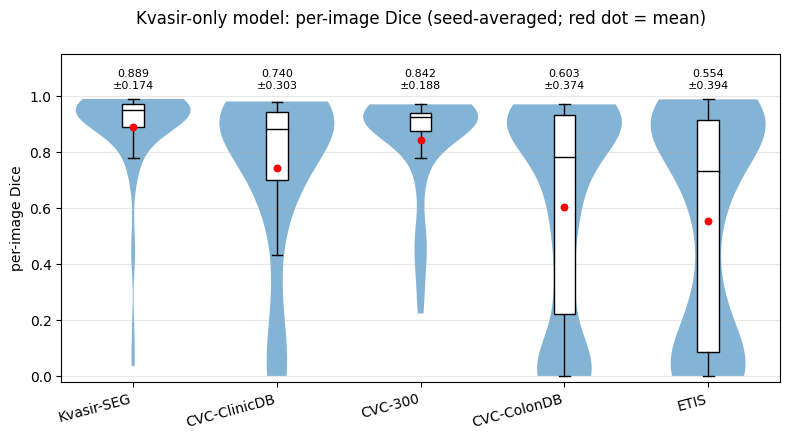

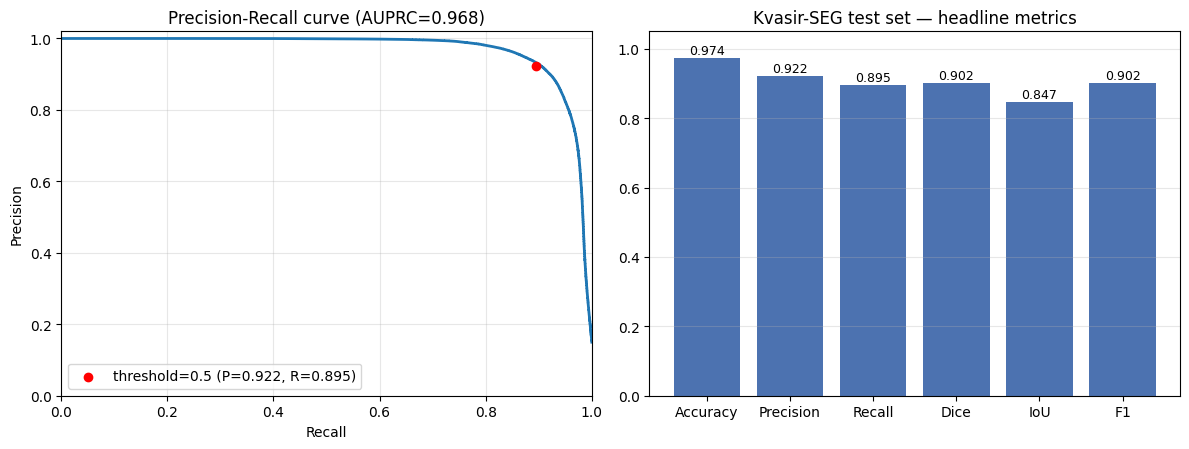

Kvasir-SEG test set: HD95 = 32.93 px  (95% CI [23.45, 43.41])  | 0/100 images had an empty prediction or mask (penalised at the image diagonal)


{'hd95_mean': 32.92614970753581,
 'hd95_CI95': (23.450009358192062, 43.40990277610298),
 'n_empty': 0}

In [32]:
show_model_results("kvasir_main", KV_DIR, "Kvasir-only model")

model = load_trained(build, f"{KV_DIR}/kvasir_main_seed{SEEDS[0]}.weights.h5")
Xte, Yte = D["kvasir"]["test"]
summ, per, probs = evaluate_arrays(model, Xte, Yte)
pr_curve_and_bar(model, Xte, Yte, summ, title="Kvasir-SEG test set — headline metrics")
hd95_report(model, Xte, Yte, label="Kvasir-SEG test set: ")   # review §3: "lead with mDice/mIoU; add HD95"

## K4 — Polyp-size stratification + failure cases

,mean Dice,n images
Small,0.848,33.0
Medium,0.947,33.0
Large,0.911,34.0


size thresholds (pixels): (8753.530000000002, 21385.46) | g (area fraction) at these cuts: {'p33': 0.071, 'p66': 0.173}
Note (review 2.6): small tertiles cover a small area fraction g, so XAI's top-g IoU ceiling (K7) is naturally lower there -- expected, not a bug.
tiny (<2.5% area): 8 images | mean Dice 0.720
per-image Dice mean/median/std: 0.902 0.957 0.156


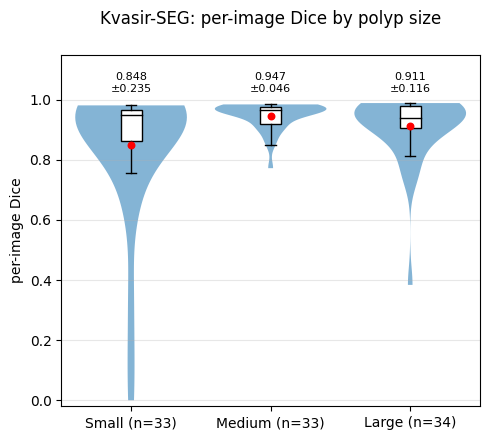

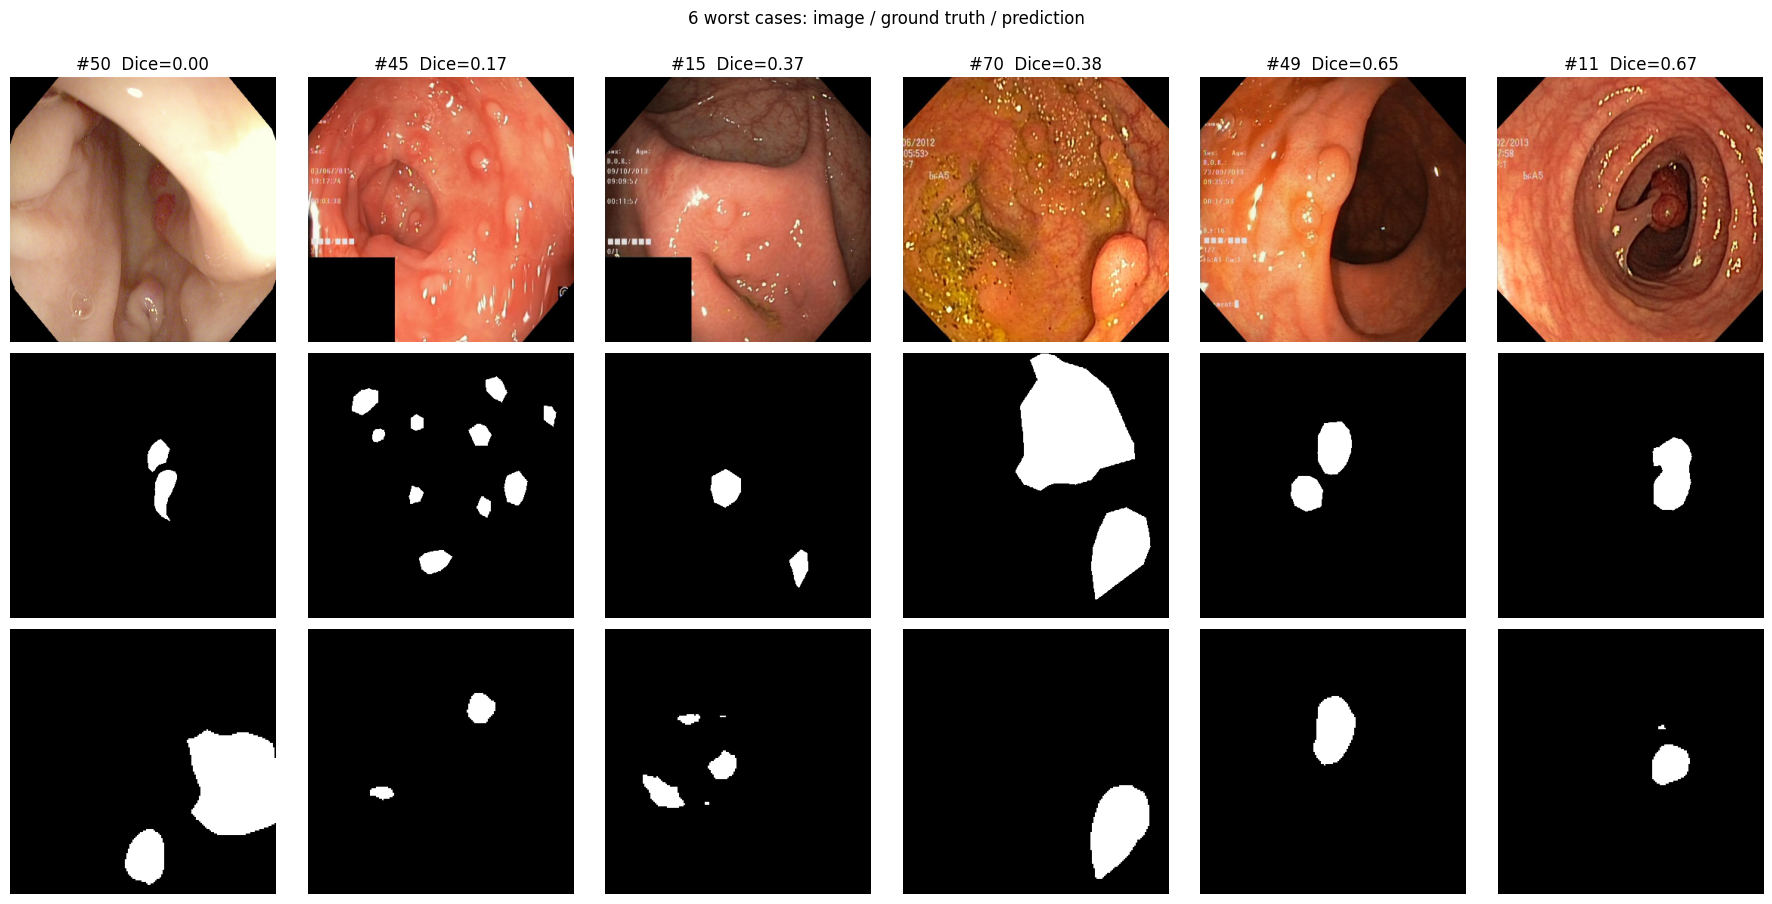

In [34]:
lab, frac, th = size_bins(Yte)
bins = dice_by_bin(per["dice"], lab)
display(pd.DataFrame({b: {"mean Dice": round(v[0], 3), "n images": v[1]} for b, v in bins.items()}).T)
print("size thresholds (pixels):", th, "| g (area fraction) at these cuts:", {k: round(v/IMG_SIZE**2,3) for k,v in zip(("p33","p66"),th)})
print("Note (review 2.6): small tertiles cover a small area fraction g, so XAI's top-g IoU ceiling (K7) is naturally lower there -- expected, not a bug.")
tiny = frac < 0.025
print(f"tiny (<2.5% area): {int(tiny.sum())} images", f"| mean Dice {per['dice'][tiny].mean():.3f}" if tiny.any() else "")
print("per-image Dice mean/median/std:", round(per["dice"].mean(), 3), round(float(np.median(per["dice"])), 3), round(per["dice"].std(), 3))
violin_plot({f"{b} (n={v[1]})": per["dice"][lab == b] for b, v in bins.items()}, "Kvasir-SEG: per-image Dice by polyp size")

worst = np.argsort(per["dice"])[:6]
fig, ax = plt.subplots(3, len(worst), figsize=(3 * len(worst), 9), squeeze=False)
for j, i in enumerate(worst):
    ax[0, j].imshow(Xte[i]); ax[0, j].set_title(f"#{i}  Dice={per['dice'][i]:.2f}")
    ax[1, j].imshow(Yte[i, ..., 0], cmap="gray"); ax[2, j].imshow(probs[i, ..., 0] > 0.5, cmap="gray")
    for r in range(3): ax[r, j].axis("off")
ax[0, 0].set_ylabel("image"); fig.suptitle("6 worst cases: image / ground truth / prediction", y=1.0)
plt.tight_layout(); plt.show()

## K5 — Robustness (poora test set, 5 corruptions × severity 0..5; 0 = clean; relative robustness)

,sev 0,sev 1,sev 2,sev 3,sev 4,sev 5
Gaussian Noise,0.902,0.890,0.865,0.804,0.692,0.498
Gaussian Blur,0.902,0.900,0.896,0.865,0.842,0.819
Brightness/Contrast,0.902,0.904,0.901,0.896,0.890,0.873
JPEG Compression,0.902,0.905,0.904,0.906,0.869,0.679
Motion Blur,0.902,0.890,0.845,0.774,0.733,0.670


,relative robustness (1.0 = koi girawat nahi)
Gaussian Noise,0.831
Gaussian Blur,0.958
Brightness/Contrast,0.990
JPEG Compression,0.945
Motion Blur,0.867
overall,0.918


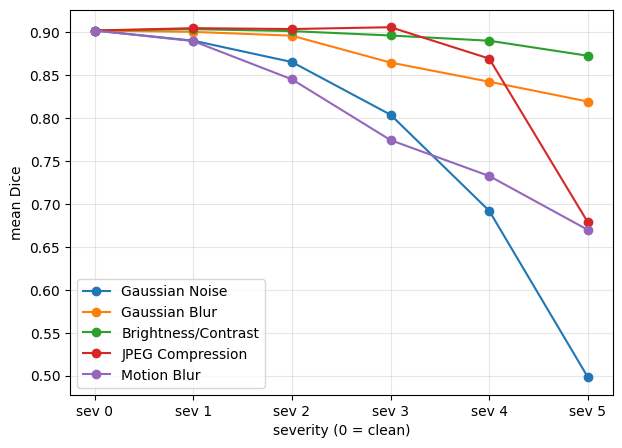

In [35]:
rb = robustness_eval(model, Xte, Yte)
df = pd.DataFrame(rb, index=[0, 1, 2, 3, 4, 5]).T
df.columns = [f"sev {c}" for c in df.columns]
display(df.round(3))
display(pd.Series(relative_robustness(rb)).round(3).to_frame("relative robustness (1.0 = koi girawat nahi)"))
df.T.plot(marker="o", figsize=(7, 5)); plt.xlabel("severity (0 = clean)"); plt.ylabel("mean Dice"); plt.grid(alpha=0.3); plt.show()

## K6 — Explainability: Grad-CAM++ (asli) + LIME + center/random baselines + deletion/insertion + model-randomisation
Ek hi protocol (`xai_full_eval`): layer `dec4_relu2`, LIME 150 segments × 1000 samples, n >= 100 Grad-CAM++ (poora test set), n >= 50 LIME.

,method,metric,mean,ci95_low,ci95_high,n
0,gradcam++,pointing_game,0.9900,0.9700,1.0000,100
1,gradcam++,energy_pg,0.9566,0.9284,0.9775,100
2,gradcam++,iou_topg,0.8583,0.8213,0.8899,100
3,gradcam++,auroc,0.9700,0.9532,0.9834,100
4,gradcam++,auprc,0.9421,0.9088,0.9685,100
5,center_prior,pointing_game,0.4400,0.3500,0.5400,100
6,center_prior,energy_pg,0.2494,0.2159,0.2822,100
7,center_prior,iou_topg,0.2646,0.2241,0.3073,100
8,center_prior,auroc,0.8353,0.8154,0.8569,100
9,center_prior,auprc,0.4189,0.3647,0.4749,100


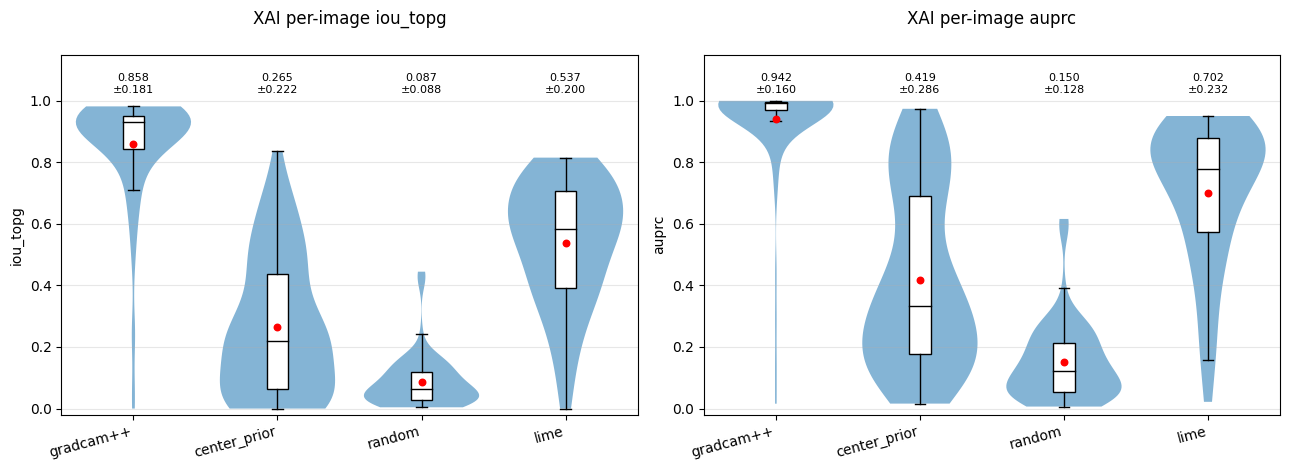

,mean over images
auprc_trained,0.953
spearman_random_all,0.167
auprc_random_all,0.188
spearman_random_decoder,0.170
auprc_random_decoder,0.112


Model-randomisation sanity check: Spearman correlation BAHUT KAM honi chahiye aur AUPRC_random << AUPRC_trained -- dono confirm karte hain ke Grad-CAM++ model ke seekhe hue weights par depend karta hai, random noise par nahi.


In [16]:
res_xai = xai_full_eval(model, Xte, Yte, n_gc=N_GC, n_lime=N_LIME, lime_segments=150, lime_samples=1000)
xai_tab = xai_report(res_xai)
display(xai_tab)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axs, ["iou_topg", "auprc"]):
    g = {m: pd.to_numeric(d[metric], errors="coerce").dropna().values for m, d in res_xai.items() if metric in d.columns}
    violin_plot(g, f"XAI per-image {metric}", ylabel=metric, ax=ax, rotate=15)
plt.tight_layout(); plt.show()

rc = randomization_check(model, lambda: build_unet_resnet50(IMG_SIZE, weights=None), Xte, Yte, n=5 if QUICK_TEST else 20)
display(rc.mean().round(3).to_frame("mean over images"))
print("Model-randomisation sanity check: Spearman correlation BAHUT KAM honi chahiye aur AUPRC_random << AUPRC_trained -- dono confirm karte hain ke Grad-CAM++ model ke seekhe hue weights par depend karta hai, random noise par nahi.")

### K6b — XAI figure (Image | GT | Prediction | Grad-CAM++ | LIME)  [best / median / worst case]

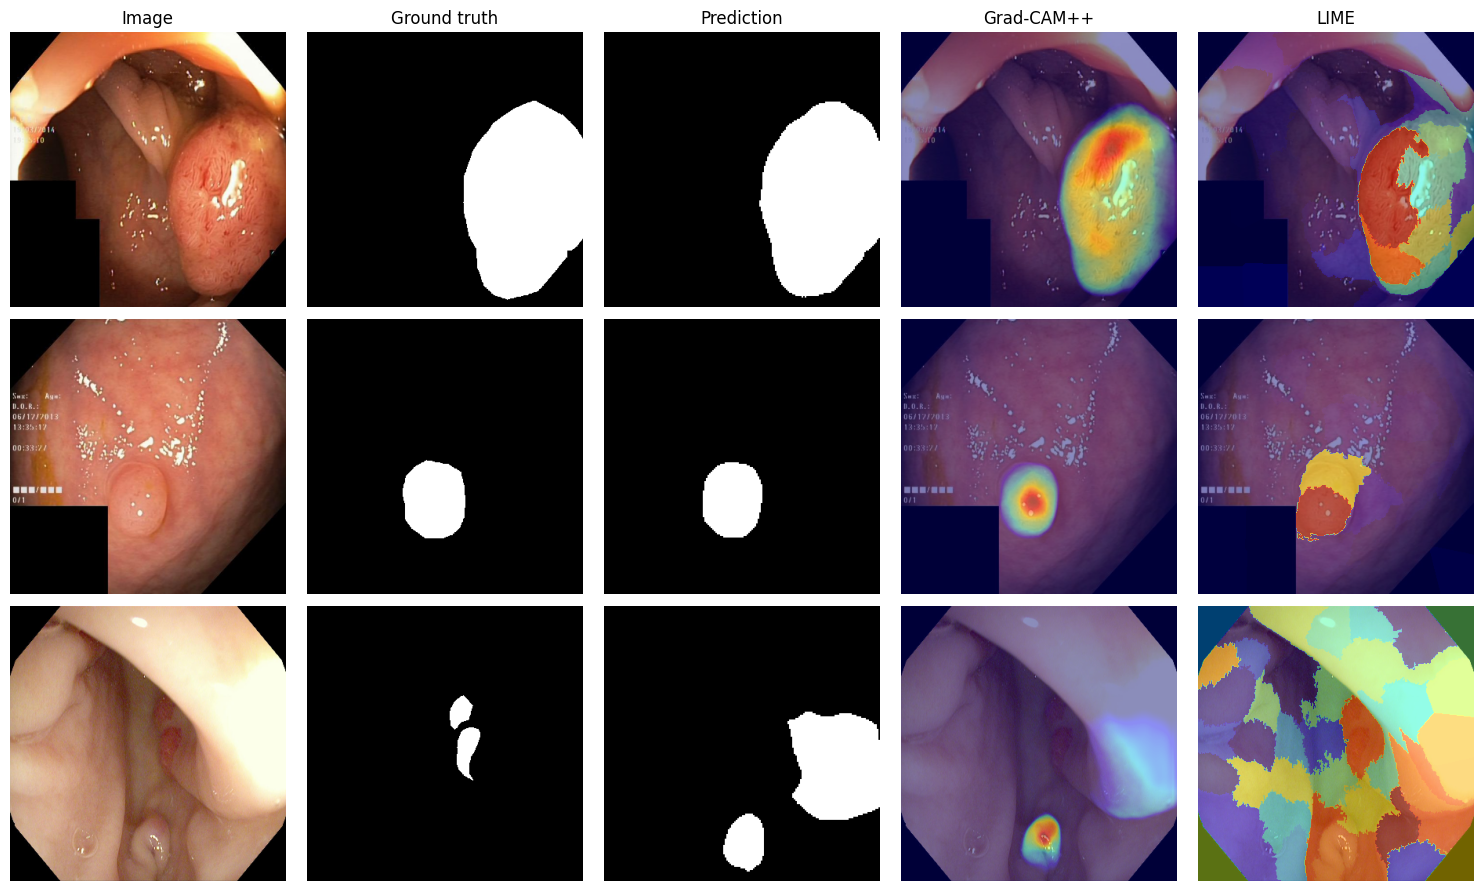

In [17]:
order = np.argsort(per["dice"]); idxs = [order[-1], order[len(order) // 2], order[0]]
xai_figure(model, Xte, Yte, idxs, lime_samples=300)

## K7 — Ablation: **architecture issue (review 2.3)** + frozen encoder + no-ImageNet + CLAHE
Sab configs SAME epoch budget (`EPOCHS`), same preprocessing (`preprocess_input` har jagah -- review 2.7 ka bug yahan nahi), multi-seed + paired Wilcoxon + Holm + bootstrap CI.

Review 2.3 ne paper ke apne Table X ka hawala diya tha: **−CBAM, −Deep Supervision, aur −Attention Gate alag-alag** (ek waqt mein ek component hatakar) Full model se behtar nikle the. Wahi replication protocol yahan dobara hai, is baar bug-free preprocessing aur matched-budget ke saath: har component ek-ek karke poore model (ASPP + attention-gated residual decoder + CBAM) se hataya gaya hai, **same `dec4_relu2` layer naam** sab variants mein, taake Grad-CAM++ ek hi protocol se chale (K7b).

Epoch 1/40
102/102 - 19s - loss: 0.3899 - dice_coef: 0.6961 - val_loss: 0.7903 - val_dice_coef: 0.5325 - lr: 1.0000e-04 - 19s/epoch - 182ms/step
Epoch 2/40
102/102 - 9s - loss: 0.2824 - dice_coef: 0.7803 - val_loss: 0.3050 - val_dice_coef: 0.7920 - lr: 1.0000e-04 - 9s/epoch - 90ms/step
Epoch 3/40
102/102 - 9s - loss: 0.2500 - dice_coef: 0.8020 - val_loss: 0.2478 - val_dice_coef: 0.8174 - lr: 1.0000e-04 - 9s/epoch - 90ms/step
Epoch 4/40
102/102 - 8s - loss: 0.2240 - dice_coef: 0.8274 - val_loss: 0.2247 - val_dice_coef: 0.8158 - lr: 1.0000e-04 - 8s/epoch - 82ms/step
Epoch 5/40
102/102 - 8s - loss: 0.2101 - dice_coef: 0.8335 - val_loss: 0.2304 - val_dice_coef: 0.8124 - lr: 1.0000e-04 - 8s/epoch - 83ms/step
Epoch 6/40
102/102 - 9s - loss: 0.1981 - dice_coef: 0.8392 - val_loss: 0.1988 - val_dice_coef: 0.8313 - lr: 1.0000e-04 - 9s/epoch - 91ms/step
Epoch 7/40
102/102 - 8s - loss: 0.1803 - dice_coef: 0.8547 - val_loss: 0.2245 - val_dice_coef: 0.8057 - lr: 1.0000e-04 - 8s/epoch - 83ms/step
Epo

2026-10-09 08:00:48.509720: E tensorflow/compiler/xla/stream_executor/gpu/gpu_cudamallocasync_allocator.cc:306] gpu_async_0 cuMemAllocAsync failed to allocate 6679429120 bytes: CUDA error: out of memory (CUDA_ERROR_OUT_OF_MEMORY)
 Reported by CUDA: Free memory/Total memory: 1552154624/10345644032
2026-10-09 08:00:48.509758: E tensorflow/compiler/xla/stream_executor/gpu/gpu_cudamallocasync_allocator.cc:311] Stats: Limit:                      8258846720
InUse:                      3185110961
MaxInUse:                   4992370313
NumAllocs:                    85913823
MaxAllocSize:               2310889488
Reserved:                            0
PeakReserved:                        0
LargestFreeBlock:                    0

2026-10-09 08:00:48.509808: E tensorflow/compiler/xla/stream_executor/gpu/gpu_cudamallocasync_allocator.cc:63] Histogram of current allocation: (allocation_size_in_bytes, nb_allocation_of_that_sizes), ...;
2026-10-09 08:00:48.509818: E tensorflow/compiler/xla/stream_exe

102/102 - 56s - loss: 0.4420 - dice_coef: 0.4654 - val_loss: 0.5043 - val_dice_coef: 0.3668 - lr: 1.0000e-04 - 56s/epoch - 546ms/step
Epoch 2/40
102/102 - 17s - loss: 0.2202 - dice_coef: 0.8011 - val_loss: 0.2032 - val_dice_coef: 0.8153 - lr: 1.0000e-04 - 17s/epoch - 162ms/step
Epoch 3/40
102/102 - 17s - loss: 0.1790 - dice_coef: 0.8396 - val_loss: 0.1808 - val_dice_coef: 0.8231 - lr: 1.0000e-04 - 17s/epoch - 162ms/step
Epoch 4/40
102/102 - 17s - loss: 0.1527 - dice_coef: 0.8625 - val_loss: 0.1849 - val_dice_coef: 0.8385 - lr: 1.0000e-04 - 17s/epoch - 163ms/step
Epoch 5/40
102/102 - 15s - loss: 0.1520 - dice_coef: 0.8588 - val_loss: 0.1776 - val_dice_coef: 0.8367 - lr: 1.0000e-04 - 15s/epoch - 150ms/step
Epoch 6/40
102/102 - 17s - loss: 0.1456 - dice_coef: 0.8657 - val_loss: 0.1582 - val_dice_coef: 0.8526 - lr: 1.0000e-04 - 17s/epoch - 163ms/step
Epoch 7/40
102/102 - 17s - loss: 0.1315 - dice_coef: 0.8807 - val_loss: 0.1174 - val_dice_coef: 0.8920 - lr: 1.0000e-04 - 17s/epoch - 164ms/s

,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm,"HD95 (px, seed0)"
0,"Proposed (plain, fine-tuned)",0.8891,0.0082,0.0000,"[0.000, 0.000]",NaN,NaN,32.93
1,Frozen encoder,0.8453,0.0035,-0.0437,"[-0.065, -0.023]",0.0000,0.0000,59.75
2,No ImageNet (scratch),0.7949,0.0184,-0.0942,"[-0.129, -0.065]",0.0000,0.0000,61.18
3,+ CLAHE,0.8801,0.0091,-0.0090,"[-0.022, 0.002]",0.4895,0.4931,46.32
4,Complex: Full (ASPP+Attn+CBAM),0.8921,0.0040,0.0030,"[-0.009, 0.014]",0.2466,0.4931,32.79
5,Complex: -CBAM,0.8918,0.0055,0.0027,"[-0.006, 0.011]",0.1210,0.4839,31.55
6,Complex: -Attention Gate,0.8929,0.0037,0.0038,"[-0.006, 0.014]",0.1477,0.4839,32.03


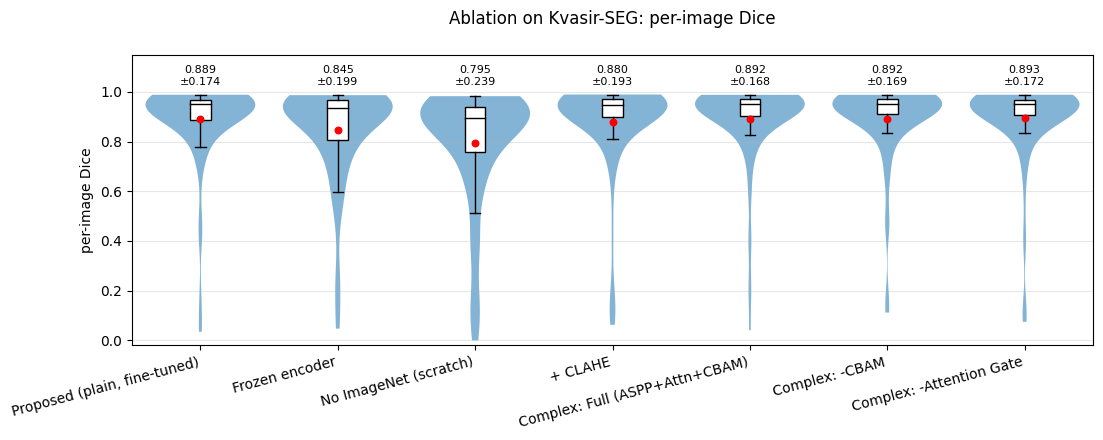


Review 2.3 ka jawab: agar koi bhi Complex row 'Proposed (plain)' se significantly behtar NAHI (Holm-corrected p >= 0.05),
to plain ResNet-50 U-Net hi justified main architecture hai -- complex decoder ke modules (ek-ek karke hatane par) 
accuracy mein translate nahi hote, jaisa paper ke apne Table X mein pehle bhi dikha tha.


In [18]:
if RUN_ABLATION:
    free_gpu_memory()
    only = {"kvasir": TEST["kvasir"]}
    run_seeds("kvasir_frozen",  SEEDS, lambda: build_unet_resnet50(IMG_SIZE, freeze_encoder=True), D["kvasir"]["train"], D["kvasir"]["val"], only, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR)
    run_seeds("kvasir_scratch", SEEDS, lambda: build_unet_resnet50(IMG_SIZE, weights=None),         D["kvasir"]["train"], D["kvasir"]["val"], only, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR)
    run_seeds("kvasir_clahe",   SEEDS, build, D["kvasir"]["train"], D["kvasir"]["val"], only, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR, clahe=True)

    # Full complex model + each component removed ONE AT A TIME (review 2.3's exact replication protocol)
    COMPLEX_VARIANTS = {
        "kvasir_complex":           dict(use_cbam=True,  use_attention_gate=True),    # Full (ASPP+Attn+CBAM)
        "kvasir_complex_no_cbam":   dict(use_cbam=False, use_attention_gate=True),    # -CBAM
        "kvasir_complex_no_attn":  dict(use_cbam=True,  use_attention_gate=False),   # -Attention Gate
    }
    for tag, kw in COMPLEX_VARIANTS.items():
        run_seeds(tag, SEEDS, lambda kw=kw: build_complex_kvasir(IMG_SIZE, deep_supervision=False, **kw),
                  D["kvasir"]["train"], D["kvasir"]["val"], only, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR)
    if RUN_COMPLEX_DS:   # Full + Deep Supervision (separate multi-output training loop, see kv_extra.py)
        run_seeds_complex_ds("kvasir_complex_ds", SEEDS, IMG_SIZE, D["kvasir"]["train"], D["kvasir"]["val"], only, epochs=EPOCHS, batch=BATCH, out_dir=KV_DIR)

    per = {"Proposed (plain, fine-tuned)":      load_dice("kvasir_main",            SEEDS, "kvasir", KV_DIR),
           "Frozen encoder":                    load_dice("kvasir_frozen",          SEEDS, "kvasir", KV_DIR),
           "No ImageNet (scratch)":              load_dice("kvasir_scratch",        SEEDS, "kvasir", KV_DIR),
           "+ CLAHE":                            load_dice("kvasir_clahe",          SEEDS, "kvasir", KV_DIR),
           "Complex: Full (ASPP+Attn+CBAM)":     load_dice("kvasir_complex",         SEEDS, "kvasir", KV_DIR),
           "Complex: -CBAM":                     load_dice("kvasir_complex_no_cbam", SEEDS, "kvasir", KV_DIR),
           "Complex: -Attention Gate":           load_dice("kvasir_complex_no_attn", SEEDS, "kvasir", KV_DIR)}
    if RUN_COMPLEX_DS and have("kvasir_complex_ds", KV_DIR):
        per["Complex: Full + Deep Supervision"] = load_dice("kvasir_complex_ds", SEEDS, "kvasir", KV_DIR)
    tab = compare_table(per, "Proposed (plain, fine-tuned)")
    # HD95 (review §3: "lead with mDice/mIoU; add HD95") for the seed[0] checkpoint of every config
    tag_of = {"Proposed (plain, fine-tuned)": "kvasir_main", "Frozen encoder": "kvasir_frozen",
              "No ImageNet (scratch)": "kvasir_scratch", "+ CLAHE": "kvasir_clahe",
              "Complex: Full (ASPP+Attn+CBAM)": "kvasir_complex", "Complex: -CBAM": "kvasir_complex_no_cbam",
              "Complex: -Attention Gate": "kvasir_complex_no_attn", "Complex: Full + Deep Supervision": "kvasir_complex_ds"}
    build_of = {"Proposed (plain, fine-tuned)": build, "Frozen encoder": build, "No ImageNet (scratch)": build, "+ CLAHE": build,
                "Complex: Full (ASPP+Attn+CBAM)": lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=False, **COMPLEX_VARIANTS["kvasir_complex"]),
                "Complex: -CBAM": lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=False, **COMPLEX_VARIANTS["kvasir_complex_no_cbam"]),
                "Complex: -Attention Gate": lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=False, **COMPLEX_VARIANTS["kvasir_complex_no_attn"]),
                "Complex: Full + Deep Supervision": lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=True, use_cbam=True, use_attention_gate=True)}
    hd95s = []
    for row_name in tab["config"]:
        if row_name not in tag_of or row_name not in build_of or not have(tag_of[row_name], KV_DIR):
            hd95s.append(np.nan); continue
        mdl = load_trained(build_of[row_name], f"{KV_DIR}/{tag_of[row_name]}_seed{SEEDS[0]}.weights.h5")
        probs_i = predict_probs(mdl, to_model_input(Xte), out_idx=0)
        hd, _ = hd95_batch(Yte, binarize(probs_i, 0.5))
        hd95s.append(round(float(hd.mean()), 2))
        del mdl; free_gpu_memory()
    tab["HD95 (px, seed0)"] = hd95s
    display(tab)
    violin_plot({n: np.mean(np.stack(v), 0) for n, v in per.items()}, "Ablation on Kvasir-SEG: per-image Dice", rotate=15)
    print("\nReview 2.3 ka jawab: agar koi bhi Complex row 'Proposed (plain)' se significantly behtar NAHI (Holm-corrected p >= 0.05),\n"
          "to plain ResNet-50 U-Net hi justified main architecture hai -- complex decoder ke modules (ek-ek karke hatane par) \n"
          "accuracy mein translate nahi hote, jaisa paper ke apne Table X mein pehle bhi dikha tha.")
else:
    print("RUN_ABLATION = False -> skip")

### K7b — Ablation XAI: plain vs complex (SAME `dec4_relu2` layer, SAME n -> review 2.6's 'different layers' fix)

In [19]:
if RUN_ABLATION and have("kvasir_complex", KV_DIR):
    complex_model = load_trained(lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=False), f"{KV_DIR}/kvasir_complex_seed{SEEDS[0]}.weights.h5")
    res_complex = xai_full_eval(complex_model, Xte, Yte, n_gc=N_GC, n_lime=N_LIME, lime_segments=150, lime_samples=1000)
    tab_plain = xai_report(res_xai); tab_plain.insert(0, "model", "Plain")
    tab_complex = xai_report(res_complex); tab_complex.insert(0, "model", "Complex")
    both = pd.concat([tab_plain, tab_complex], ignore_index=True)
    display(both.pivot_table(index=["method", "metric"], columns="model", values="mean").round(3))
    free_gpu_memory()
else:
    print("Ablation nahi chali ya kvasir_complex results nahi mile -> is cell ko skip kiya.")

model                                       Complex  Plain
method                       metric                       
center_prior                 auprc            0.419  0.419
                             auroc            0.835  0.835
                             energy_pg        0.249  0.249
                             iou_topg         0.265  0.265
                             pointing_game    0.440  0.440
gradcam++                    auprc            0.939  0.942
                             auroc            0.981  0.970
                             energy_pg        0.665  0.957
                             iou_topg         0.842  0.858
                             pointing_game    0.610  0.990
gradcam++ deletion/insertion deletion_auc     0.164  0.252
                             insertion_auc    0.884  0.891
lime                         auprc            0.340  0.702
                             auroc            0.594  0.879
                             energy_pg        0.301  0.482
                             iou_topg         0.236  0.537
                             pointing_game    0.500  0.800
random                       auprc            0.150  0.150
                             auroc            0.500  0.500
                             energy_pg        0.150  0.150
                             iou_topg         0.087  0.087
                             pointing_game    0.150  0.150

### K7c — TTA / post-processing / threshold isolation (review 2.3: *"the real difference must be TTA, post-processing, threshold, or split"*)
Same trained weights (`kvasir_main`, seed 0), sirf inference-time settings badalte hain — koi dobara training nahi. Threshold validation set par grid-search hota hai (31 values, [0.2, 0.8]), jaisa paper khud karta hai.

In [20]:
tta_tab = tta_post_threshold_ablation(model, *D["kvasir"]["val"], Xte, Yte)
display(tta_tab)
print("Ye table dikhati hai ke headline Dice (K3) ka kitna hissa architecture se aata hai, aur kitna TTA/post-processing/threshold-tuning se --\n"
      "jo bilkul wahi sawal hai jo review ne uthaya tha.")

,setting,mDice,mIoU,Δ vs (a)
0,"(a) default (thr=0.5, no TTA, no post)",0.9019,0.8466,0.0000
1,(b) + TTA (4-way flip),0.8995,0.8472,-0.0024
2,(c) + largest-component post-processing,0.8929,0.8359,-0.0090
3,"(d) + TTA + post + val-tuned threshold (thr=0.500, val mDice=0.922)",0.8913,0.8370,-0.0106


Ye table dikhati hai ke headline Dice (K3) ka kitna hissa architecture se aata hai, aur kitna TTA/post-processing/threshold-tuning se --
jo bilkul wahi sawal hai jo review ne uthaya tha.


## K8 — Efficiency (params / FLOPs / latency) — 352 resolution par

In [36]:
eff = efficiency_report(model, IMG_SIZE)   # plain model (proposed); FLOPs vs MACs ka unit published tables ke saath match karein
display(pd.DataFrame([eff]).round(3))

,params_M,gflops,latency_ms,fps
0,43.944,67.05,35.199,28.41


## K9 — Cross-dataset generalisation matrix (zero-shot): Kvasir-trained model → CVC-ClinicDB, CVC-300, CVC-ColonDB, ETIS
Training dobara nahi hoti — K2 ka `run_seeds` ne sab 5 test sets par pehle hi evaluate karke save kiya tha.

,test set,mDice (mean ± SD over seeds),n images
0,Kvasir-SEG,0.889 ± 0.008,100
1,CVC-ClinicDB,0.740 ± 0.035,62
2,CVC-300,0.842 ± 0.026,60
3,CVC-ColonDB,0.603 ± 0.035,380
4,ETIS,0.554 ± 0.034,196


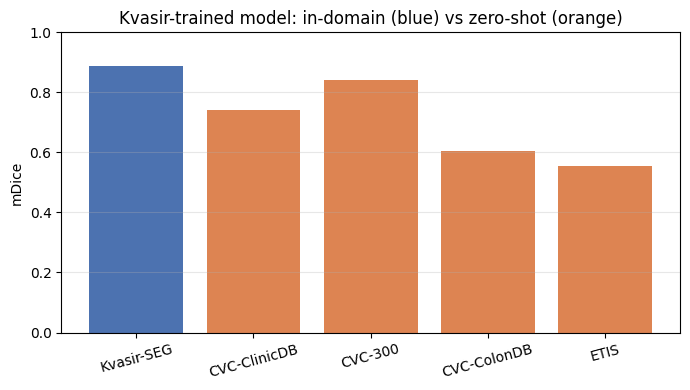

In-domain (Kvasir) mDice = 0.889 | drop on unseen sets: {'CVC-ClinicDB': 0.149, 'CVC-300': 0.047, 'CVC-ColonDB': 0.286, 'ETIS': 0.335}

Note: ye Kvasir-SEG ka OWN zero-shot row hai. CVC-trained model ka row, aur dono-trained (pooled/federated) models ka,
companion CVC/federated notebook mein hain -- us notebook ki results_cvc / results_fed folders se Kvasir-only row ke saath combine ho sakte hain.


In [22]:
rows = []
files = sorted(glob.glob(f"{KV_DIR}/kvasir_main_seed*.npz"))
if not files:
    print("kvasir_main results nahi mile -> pehle K2 chalayein.")
else:
    data = [np.load(f) for f in files]
    means = []
    for k in TEST:
        m = [d[f"dice__{k}"].mean() for d in data]
        rows.append({"test set": NAMES[k], "mDice (mean ± SD over seeds)": pm(m), "n images": TEST[k][0].shape[0]})
        means.append(float(np.mean(m)))
    display(pd.DataFrame(rows))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(range(len(TEST)), means, color=["#4C72B0" if k == "kvasir" else "#DD8452" for k in TEST])
    ax.set_xticks(range(len(TEST))); ax.set_xticklabels([NAMES[k] for k in TEST], rotation=15)
    ax.set_ylim(0, 1.0); ax.set_ylabel("mDice"); ax.set_title("Kvasir-trained model: in-domain (blue) vs zero-shot (orange)"); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()
    base = means[list(TEST).index("kvasir")]
    print("In-domain (Kvasir) mDice =", round(base, 3), "| drop on unseen sets:",
          {NAMES[k]: round(base - means[j], 3) for j, k in enumerate(TEST) if k != "kvasir"})
    print("\nNote: ye Kvasir-SEG ka OWN zero-shot row hai. CVC-trained model ka row, aur dono-trained (pooled/federated) models ka,\n"
          "companion CVC/federated notebook mein hain -- us notebook ki results_cvc / results_fed folders se Kvasir-only row ke saath combine ho sakte hain.")

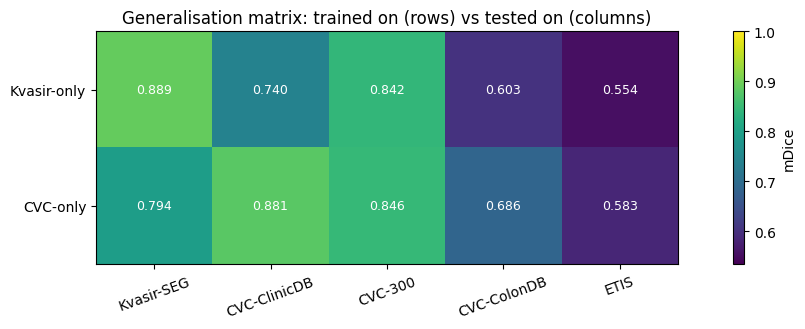

In [38]:
def _row_means(tag, folder):
    files = sorted(glob.glob(f"{folder}/{tag}_seed*.npz"))
    if not files:
        return None
    data = [np.load(f) for f in files]
    return {k: float(np.mean([d[f"dice__{k}"].mean() for d in data])) for k in TEST if all(f"dice__{k}" in d.files for d in data)}

MATRIX_MODELS = {"Kvasir-only": ("kvasir_main", KV_DIR)}
if os.path.isdir("results_cvc"):   # companion CVC notebook ke results agar isi folder mein maujood hain
    MATRIX_MODELS["CVC-only"] = ("cvc_main", "results_cvc")

gen_means = {}
for name, (tag, folder) in MATRIX_MODELS.items():
    r = _row_means(tag, folder)
    if r:
        gen_means[name] = [r.get(k, np.nan) for k in TEST]

if not gen_means:
    print("Koi saved result nahi mila -> pehle K2 chalayein.")
else:
    M = np.array(list(gen_means.values()), float)
    fig, ax = plt.subplots(figsize=(1.9 * len(TEST) + 2, 0.7 * len(gen_means) + 2))
    im = ax.imshow(M, vmin=max(0.0, np.nanmin(M) - 0.02), vmax=1.0, cmap="viridis")
    ax.set_xticks(range(len(TEST))); ax.set_xticklabels([NAMES[k] for k in TEST], rotation=20)
    ax.set_yticks(range(len(gen_means))); ax.set_yticklabels(list(gen_means))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, "-" if np.isnan(M[i, j]) else f"{M[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
    plt.colorbar(im, label="mDice")
    ax.set_title("Generalisation matrix: trained on (rows) vs tested on (columns)")
    plt.tight_layout(); plt.show()
    if "CVC-only" not in gen_means:
        print("Note: sirf Kvasir-only row dikhayi -- CVC-trained model ka row add karne ke liye companion CVC/federated\n"
              "notebook ka 'results_cvc' folder isi working directory mein copy kar dein, ye cell dobara chalayein.")

## K10 — SOTA comparison table (Kvasir-only vs published numbers, mDice)
Published numbers un papers se hain jo **900 Kvasir + 550 CVC ek saath** train karte hain (PraNet protocol); hamara "Kvasir-only" row isi protocol ke 5 test sets par evaluate hota hai lekin **sirf Kvasir par train** hua hai -- is liye yeh like-for-like NAHI hai, sirf reference ke liye.

In [37]:
cols  = ["kvasir", "cvc", "cvc300", "colondb", "etis"]
published = {   # mDice. VERIFIED from the original papers (protocol confirmed in HarDNet-MSEG and UACANet papers).
    "PraNet (MICCAI'20)":      ([0.898, 0.899, 0.871, 0.709, 0.628], "PraNet paper; same values in HarDNet-MSEG Tab.2-3 and UACANet Tab.3-4", 32.55, 13.86),
    "HarDNet-MSEG (arXiv'21)": ([0.912, 0.932, 0.887, 0.731, 0.677], "arXiv:2101.07172 Tab.2-3 (their CVC-T = CVC-300)", 33.34, 12.04),
    "UACANet-S (ACM MM'21)":   ([0.905, 0.916, 0.902, 0.783, 0.694], "arXiv:2107.02368 Tab.3-4 -- Params/FLOPs not in the paper, verify separately", None, None),
    "UACANet-L (ACM MM'21)":   ([0.912, 0.926, 0.910, 0.751, 0.766], "arXiv:2107.02368 Tab.3-4 -- Params/FLOPs not in the paper, verify separately", None, None),
    "Polyp-PVT (arXiv'21)":    ([0.917, 0.937, 0.900, 0.808, 0.787], "arXiv:2108.06932 Tab.IV-VI (their Endoscene = CVC-300)", 25.11, 10.60),
}
rows = [{"method": k, **dict(zip(cols, v[0])), "Params(M)": v[2], "FLOPs(G)": v[3]} for k, v in published.items()]
if files:
    r = {"method": "Ours: Kvasir-only  [NOT like-for-like -- see note above]"}
    for c, m in zip(cols, means):
        r[c] = f"{m:.3f}"
    r["Params(M)"] = round(eff["params_M"], 2)
    r["FLOPs(G)"] = round(eff["gflops"], 2) if eff.get("gflops") is not None else None
    rows.append(r)
table = pd.DataFrame(rows).fillna("-").rename(columns=NAMES)
display(table)
print("\nSources:"); [print(f"  {k}: {v[1]}") for k, v in published.items()]
print(f"\nOurs Params/FLOPs measured directly in K8 (efficiency_report) at {IMG_SIZE}x{IMG_SIZE} -- not copied from any paper.")
print("\nTABLE NOTE (paper mein): published methods train on 900 Kvasir-SEG + 550 CVC-ClinicDB jointly and test on the five official\n"
      "PraNet test sets (Kvasir 100, CVC-ClinicDB 62, CVC-300 60, CVC-ColonDB 380, ETIS 196); mDice values copied from the respective\n"
      "papers, Params/FLOPs copied only where this paper's own Table XIII/XIV already verified them. Our 'Kvasir-only' row uses the\n"
      "SAME five test sets and the SAME 352x352 input, but is trained on Kvasir-SEG alone, so it is a harder, zero-shot comparison on\n"
      "4 of the 5 columns, not a like-for-like SOTA claim. The like-for-like (pooled Kvasir+CVC) row is reported in the companion\n"
      "CVC/federated notebook. FLOPs vs MACs: published tables often report MACs (=FLOPs/2) -- check each paper's convention before\n"
      "directly comparing to our measured FLOPs.")

,method,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS,Params(M),FLOPs(G)
0,PraNet (MICCAI'20),0.898,0.899,0.871,0.709,0.628,32.55,13.86
1,HarDNet-MSEG (arXiv'21),0.912,0.932,0.887,0.731,0.677,33.34,12.04
2,UACANet-S (ACM MM'21),0.905,0.916,0.902,0.783,0.694,-,-
3,UACANet-L (ACM MM'21),0.912,0.926,0.91,0.751,0.766,-,-
4,Polyp-PVT (arXiv'21),0.917,0.937,0.9,0.808,0.787,25.11,10.6
5,Ours: Kvasir-only [NOT like-for-like -- see note above],0.889,0.740,0.842,0.603,0.554,43.94,67.05



Sources:
  PraNet (MICCAI'20): PraNet paper; same values in HarDNet-MSEG Tab.2-3 and UACANet Tab.3-4
  HarDNet-MSEG (arXiv'21): arXiv:2101.07172 Tab.2-3 (their CVC-T = CVC-300)
  UACANet-S (ACM MM'21): arXiv:2107.02368 Tab.3-4 -- Params/FLOPs not in the paper, verify separately
  UACANet-L (ACM MM'21): arXiv:2107.02368 Tab.3-4 -- Params/FLOPs not in the paper, verify separately
  Polyp-PVT (arXiv'21): arXiv:2108.06932 Tab.IV-VI (their Endoscene = CVC-300)

Ours Params/FLOPs measured directly in K8 (efficiency_report) at 352x352 -- not copied from any paper.

TABLE NOTE (paper mein): published methods train on 900 Kvasir-SEG + 550 CVC-ClinicDB jointly and test on the five official
PraNet test sets (Kvasir 100, CVC-ClinicDB 62, CVC-300 60, CVC-ColonDB 380, ETIS 196); mDice values copied from the respective
papers, Params/FLOPs copied only where this paper's own Table XIII/XIV already verified them. Our 'Kvasir-only' row uses the
SAME five test sets and the SAME 352x352 input, but is tra

In [1]:
import pandas as pd
gmac_ours = 67.05 / 2     # TF profiler FLOPs = 2 x MACs
eff = pd.DataFrame([["PraNet", 32.55, 13.11], ["HarDNet-MSEG", 33.34, 11.38],
                    ["Polyp-PVT", 25.1, 10.0], ["Ours", 43.94, gmac_ours]],
                   columns=["method", "Params (M)", "GMac @352"])
display(eff); print("Ours / PraNet =", round(gmac_ours / 13.11, 2), "x")

,method,Params (M),GMac @352
0,PraNet,32.55,13.110
1,HarDNet-MSEG,33.34,11.380
2,Polyp-PVT,25.10,10.000
3,Ours,43.94,33.525


Ours / PraNet = 2.56 x


## K11 — Dataset-heterogeneity plot: Kvasir-SEG vs CVC-ClinicDB / CVC-ColonDB / ETIS (no model training here)
Sirf images/masks ke properties compare hote hain (polyp size, brightness) -- koi doosra model train nahi hota. Ye un domain-shift ka context deta hai jo K9 ke zero-shot drops explain karta hai.

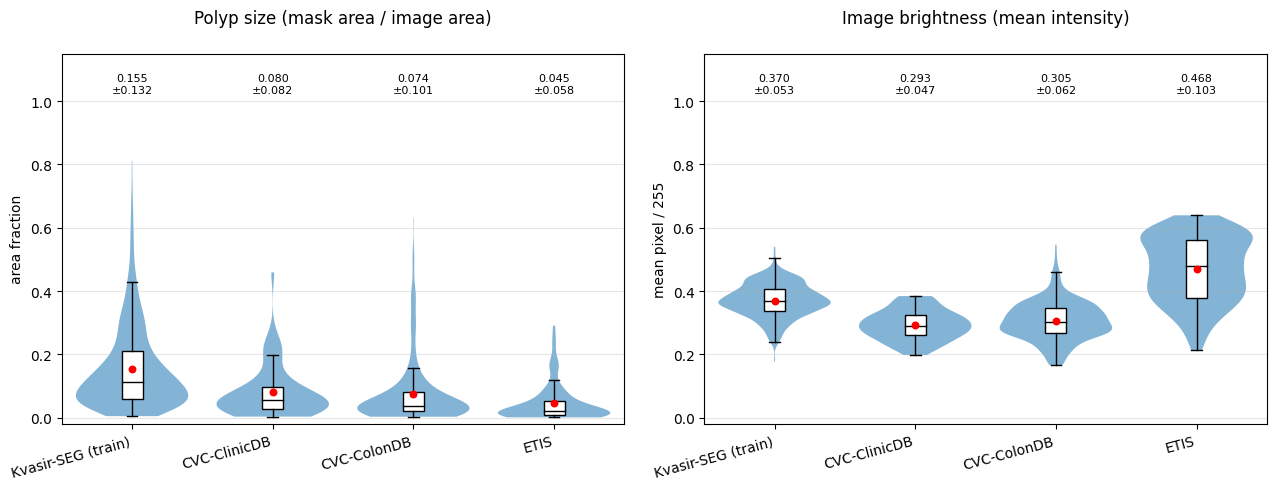

Ye panels K9 ke zero-shot mDice drops ka context dete hain: jitni zyada polyp-size/brightness distribution Kvasir se alag,
utna zyada domain shift expected hai.


In [24]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sets = {"Kvasir-SEG (train)": D["kvasir"]["train"], **{NAMES[k]: TEST[k] for k in ("cvc", "colondb", "etis") if k in TEST}}
violin_plot({n: (Y > 0.5).reshape(len(Y), -1).mean(1) for n, (X, Y) in sets.items()},
            "Polyp size (mask area / image area)", ylabel="area fraction", ax=axs[0], rotate=15)
violin_plot({n: X.reshape(len(X), -1).mean(1) / 255.0 for n, (X, Y) in sets.items()},
            "Image brightness (mean intensity)", ylabel="mean pixel / 255", ax=axs[1], rotate=15)
plt.tight_layout(); plt.show()
print("Ye panels K9 ke zero-shot mDice drops ka context dete hain: jitni zyada polyp-size/brightness distribution Kvasir se alag,\n"
      "utna zyada domain shift expected hai.")

## K12 — Split image-ID list (reproducibility) + near-duplicate sensitivity

In [25]:
rows = [{"dataset": "Kvasir-SEG", "split": sp, "image_id": os.path.basename(p)} for sp in ("train", "val") for p in D["kvasir"][f"paths_{sp}"]]
for k in TEST:
    rows += [{"dataset": NAMES[k], "split": "test", "image_id": os.path.basename(p)} for p in D[k]["paths_test"]]
split_df = pd.DataFrame(rows)
display(split_df.groupby(["dataset", "split"]).size().unstack(fill_value=0))
split_df.to_csv("kvasir_split_image_ids.csv", index=False)
print("Saved: kvasir_split_image_ids.csv -> repository mein commit karein")

PH_DIST = 8
flag = {}
for k in TEST:
    nd = near_duplicates(D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"], D[k]["paths_test"], max_dist=PH_DIST)
    flag[k] = nd["nearest_dist"] <= PH_DIST
print(f"Near-duplicate test images vs Kvasir train/val (pHash <= {PH_DIST}):", {NAMES[k]: f"{int(v.sum())}/{len(v)}" for k, v in flag.items()})
if not any(v.any() for v in flag.values()):
    print("Koi near-duplicate nahi mila -> count = 0.")
else:
    arrs = load_dice("kvasir_main", SEEDS, "kvasir", KV_DIR)
    keep = ~flag["kvasir"]
    if keep.sum() >= 5:
        full, clean = [a.mean() for a in arrs], [a[keep].mean() for a in arrs]
        print("Kvasir test mDice: full =", pm(full), "| without near-duplicates =", pm(clean), "| diff =", round(float(np.mean(clean) - np.mean(full)), 4))

split,test,train,val
dataset,,,
CVC-300,60,0,0
CVC-ClinicDB,62,0,0
CVC-ColonDB,380,0,0
ETIS,196,0,0
Kvasir-SEG,100,810,90


Saved: kvasir_split_image_ids.csv -> repository mein commit karein
Near-duplicate test images vs Kvasir train/val (pHash <= 8): {'Kvasir-SEG': '16/100', 'CVC-ClinicDB': '0/62', 'CVC-300': '1/60', 'CVC-ColonDB': '4/380', 'ETIS': '3/196'}
Kvasir test mDice: full = 0.889 ± 0.008 | without near-duplicates = 0.899 ± 0.008 | diff = 0.0095


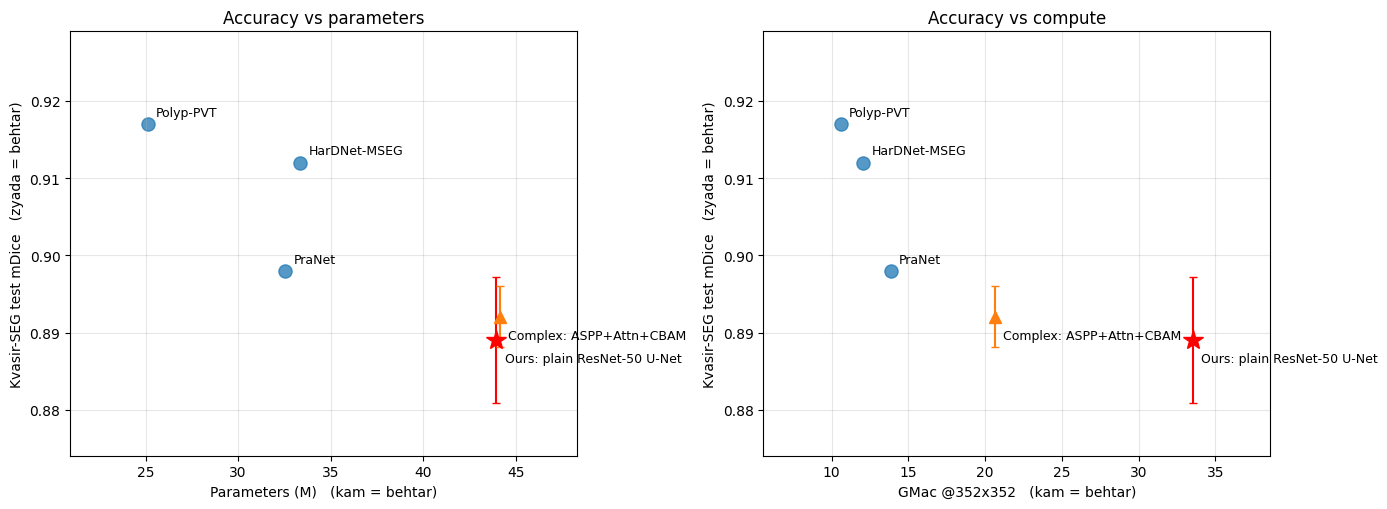

,method,Kvasir mDice,Params (M),GMac,trained on
0,PraNet,0.898,32.55,13.86,Kvasir + CVC (joint)
1,HarDNet-MSEG,0.912,33.34,12.04,Kvasir + CVC (joint)
2,Polyp-PVT,0.917,25.11,10.60,Kvasir + CVC (joint)
3,Ours: plain ResNet-50 U-Net,0.889 ± 0.008,43.94,33.50,Kvasir only
4,Complex: ASPP+Attn+CBAM,0.892 ± 0.004,44.12,20.60,Kvasir only


Notes: (1) Published mDice/Params/GMac K10 cell se copy hain (UACANet ka Params/GMac paper mein nahi, isliye plot mein nahi). (2) Ours Kvasir-only trained hai, published methods Kvasir+CVC par joint train hue -- Kvasir test par muqabla in-domain hai, par strictly like-for-like nahi. (3) Ours GMac = FLOPs x 0.5 (1 MAC = 2 FLOPs); published FLOPs ki convention (MACs ya FLOPs) source papers se verify karein.


In [39]:
# ===== K13: Accuracy-vs-efficiency plot — Kvasir-SEG (reviewer row 12: efficiency plot, purane Fig. 35 jaisa) =====
# Y = Kvasir-SEG test mDice. X = Params (M) aur GMac @352x352. Published = K10 wale numbers; Ours = yahin naap kar (efficiency_report).
PUB = {   # (mDice on Kvasir-SEG, Params M, GMac) — K10 cell ke numbers. UACANet ka Params/GMac paper mein nahi -> plot mein nahi.
    "PraNet":       (0.898, 32.55, 13.86),
    "HarDNet-MSEG": (0.912, 33.34, 12.04),
    "Polyp-PVT":    (0.917, 25.11, 10.60),
}
OURS_TO_GMAC = 0.5    # efficiency_report FLOPs deta hai (1 MAC = 2 FLOPs); published numbers GMac ke qareeb hain -> /2. Agar K8 ka 'gflops' pehle se MACs ho to 1.0 karein.


def _ours(tag, builder, label):
    if not have(tag, KV_DIR):
        print(f"[{label}] results nahi mile ({KV_DIR}/{tag}_seed*.npz) -> plot mein nahi")
        return None
    per_seed = [a.mean() for a in load_dice(tag, SEEDS, "kvasir", KV_DIR)]
    try:
        rep = efficiency_report(builder(), IMG_SIZE)
    except Exception as e:
        print(f"[{label}] Params/GMac naapi nahi ja saki: {type(e).__name__}: {str(e)[:120]}")
        return None
    finally:
        free_gpu_memory()
    return dict(label=label, mdice=float(np.mean(per_seed)), sd=float(np.std(per_seed, ddof=1)) if len(per_seed) > 1 else 0.0,
                params=float(rep["params_M"]), gmac=float(rep["gflops"]) * OURS_TO_GMAC)


ours = [r for r in (_ours("kvasir_main", build, "Ours: plain ResNet-50 U-Net"),
                    _ours("kvasir_complex", lambda: build_complex_kvasir(IMG_SIZE, deep_supervision=False), "Complex: ASPP+Attn+CBAM")) if r]

ys = [v[0] for v in PUB.values()] + [r["mdice"] for r in ours]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, key, xl in ((axs[0], "params", "Parameters (M)   (kam = behtar)"), (axs[1], "gmac", "GMac @352x352   (kam = behtar)")):
    for name, (d, p, g) in PUB.items():
        x = p if key == "params" else g
        ax.scatter(x, d, s=90, color="tab:blue", alpha=0.75)
        ax.annotate(name, (x, d), textcoords="offset points", xytext=(6, 6), fontsize=9)
    for r, marker, color in zip(ours, ("*", "^"), ("red", "tab:orange")):
        ax.errorbar(r[key], r["mdice"], yerr=r["sd"], fmt=marker, color=color, ms=15 if marker == "*" else 9, capsize=3)
        ax.annotate(r["label"], (r[key], r["mdice"]), textcoords="offset points", xytext=(6, -16), fontsize=9)
    ax.margins(x=0.22)                                   # labels kate na
    ax.set_ylim(min(ys) - 0.015, max(ys) + 0.012)
    ax.set_xlabel(xl); ax.set_ylabel("Kvasir-SEG test mDice   (zyada = behtar)"); ax.grid(alpha=0.3)
axs[0].set_title("Accuracy vs parameters"); axs[1].set_title("Accuracy vs compute")
plt.tight_layout(); plt.show()

rows = [{"method": n, "Kvasir mDice": d, "Params (M)": p, "GMac": g, "trained on": "Kvasir + CVC (joint)"} for n, (d, p, g) in PUB.items()]
rows += [{"method": r["label"], "Kvasir mDice": f"{r['mdice']:.3f} ± {r['sd']:.3f}", "Params (M)": round(r["params"], 2), "GMac": round(r["gmac"], 1), "trained on": "Kvasir only"} for r in ours]
display(pd.DataFrame(rows))
print("Notes: (1) Published mDice/Params/GMac K10 cell se copy hain (UACANet ka Params/GMac paper mein nahi, isliye plot mein nahi). "
      "(2) Ours Kvasir-only trained hai, published methods Kvasir+CVC par joint train hue -- Kvasir test par muqabla in-domain hai, par strictly like-for-like nahi. "
      "(3) Ours GMac = FLOPs x %.1f (1 MAC = 2 FLOPs); published FLOPs ki convention (MACs ya FLOPs) source papers se verify karein." % OURS_TO_GMAC)

## Reviewer ke Kvasir-specific points — kaunsa cell kya dikhata hai

| Point | Cell |
|---|---|
| Architecture: plain ResNet-50 U-Net justified over complex decoder (review 2.3) | K7, K7b |
| Architecture: −CBAM, −Attention Gate replication (same protocol as the paper's own Table X; review 2.3) | K7 (`COMPLEX_VARIANTS`) |
| "Inconsistent explanation": isolates how much of any Dice gap is TTA / post-processing / threshold vs architecture (review 2.3) | K7c |
| Preprocessing bug (review 2.7) fixed — `preprocess_input` har jagah, har ablation configuration mein | K0 (`to_model_input`), K7 |
| SOTA comparison: mDice, PraNet protocol, HarDNet-MSEG + UACANet-S/L added (review 2.2) | K10 |
| Quantitative XAI: same layer, n>=100 Grad-CAM++, LIME 150seg/1000samples/n>=50, deletion/insertion, randomisation check, mean±CI (review 2.6) | K6, K6b, K7b |
| Robustness: full test set, severity-0 clean column, relative robustness (review 2.8) | K5 |
| Statistics: 5 seeds, seed-averaged per-image Dice, paired Wilcoxon + Holm + bootstrap CI (10,000 resamples), no pseudo-replication (review 2.5) | K7 (`compare_configs`) |
| Lead with mDice/mIoU; add HD95 (review §3) | K3, K7 |
| Cross-dataset / domain-shift (review 2.4, this notebook's Kvasir-only slice of it) | K9, K11 |
| Precision-Recall curve / metrics bar chart (your request) | K3 |
| Dataset/client-heterogeneity plot (your request) | K11 |
| Reproducibility: split IDs, near-duplicate check (review 2.8 / Step 2) | K12 |

**Is notebook mein NAHI hai (jaan-boojh kar, aapke instructions ke mutabiq):** CVC-ClinicDB training, pooled (Kvasir+CVC) training, federated learning (FedAvg/FedProx/FedBN) — ye sab companion CVC/federated notebook mein hain. Is notebook ke `results_kvasir/kvasir_main_seed*.npz` files us notebook ki SOTA table aur cross-dataset matrix cells seedhe padh sakte hain (same file format, same `common_utils.py`/`tf_utils.py`).